# TUAB EEG Classical Machine-Learning Baselines

**Research project:** Region-Aware Deep Learning for Robust EEG Abnormality Detection and Interpretable Spatial Attribution

This notebook evaluates whether recording-level spectral, temporal, and regional EEG features distinguish normal from abnormal TUAB recordings. It provides leakage-safe classical baselines and a prespecified sensitivity comparison between features aggregated from all epochs (**FE-All**) and features aggregated only from QC-accepted epochs (**FE-QC**).

## Research questions

1. How well do classical models classify abnormal versus normal recordings using the 1,152 engineered features?
2. Does QC screening change discrimination, calibration-adjacent prediction confidence, or error patterns?
3. Which feature families, frequency bands, and regions contribute predictive information?
4. Are conclusions stable across patient-independent folds and feature representations?

No result should be interpreted as clinical localization or causality. The evaluation split remains locked unless `RUN_FINAL_EVALUATION` is deliberately changed to `True`.

## 1. Experimental protocol

- **Primary comparison:** FE-All versus FE-QC on the same 2,979 QC-eligible recordings.
- **Secondary comparison:** FE-All on the complete 2,993-recording cohort.
- **Development:** five-fold `StratifiedGroupKFold` within training, grouped by patient.
- **Model selection and threshold calibration:** validation split only.
- **Final reporting:** untouched evaluation split, disabled by default.
- **Primary metric:** recording-level ROC-AUC.
- **Secondary metrics:** balanced accuracy, sensitivity, specificity, precision, F1, and patient-level metrics.
- **Interpretability:** validation-only coefficients, permutation importance, grouped importance, and regional ablation.

All learned preprocessing resides inside scikit-learn pipelines. Patient identifiers, file paths, split labels, and QC-coverage variables are excluded from predictors.

## 2. Imports and reproducibility

## Environment preflight

Run this cell first—or use **Run All**. It checks that VS Code is using the project `.venv` kernel and that every package required by this notebook is installed. It does not import scientific libraries, load feature data, train models, or create outputs.


In [1]:
import importlib.metadata
import importlib.util
import sys
from pathlib import Path


def locate_project_root_for_preflight(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks").is_dir() and (candidate / "requirements.txt").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the current working directory.")


PREFLIGHT_ROOT = locate_project_root_for_preflight()
EXPECTED_PYTHON = (PREFLIGHT_ROOT / ".venv/bin/python").resolve()
ACTIVE_PYTHON = Path(sys.executable).resolve()

if EXPECTED_PYTHON.exists() and ACTIVE_PYTHON != EXPECTED_PYTHON:
    raise RuntimeError(
        "Incorrect notebook kernel.\n"
        f"Active interpreter: {ACTIVE_PYTHON}\n"
        f"Expected interpreter: {EXPECTED_PYTHON}\n"
        "In VS Code choose: Select Kernel → Python Environments → .venv."
    )

REQUIRED_IMPORTS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "pyarrow": "pyarrow",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "IPython": "IPython",
    "ipykernel": "ipykernel",
}

missing = [
    distribution
    for distribution, module in REQUIRED_IMPORTS.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    install_command = f"{EXPECTED_PYTHON} -m pip install -r '{PREFLIGHT_ROOT / 'requirements.txt'}'"
    raise ModuleNotFoundError(
        "Missing required packages: " + ", ".join(missing) + "\n"
        "Install them from a terminal with:\n" + install_command
    )

versions = {}
for distribution in REQUIRED_IMPORTS:
    try:
        versions[distribution] = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        versions[distribution] = "available (version metadata unavailable)"

print("Environment preflight: PASSED")
print("Project root:", PREFLIGHT_ROOT)
print("Python:", ACTIVE_PYTHON)
for package, version in versions.items():
    print(f"  {package}: {version}")


Environment preflight: PASSED
Project root: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML
Python: /usr/bin/python3.12
  numpy: 2.5.4
  pandas: 3.0.6
  scipy: 1.18.1
  pyarrow: 26.0.0
  joblib: 1.6.0
  matplotlib: 3.11.2
  seaborn: 0.13.2
  scikit-learn: 1.9.1
  xgboost: 3.4.1
  IPython: 9.17.1
  ipykernel: 7.4.0


In [2]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
import warnings
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    make_scorer,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

RANDOM_STATE = 42
N_SPLITS = 5
PERMUTATION_REPEATS = 5  # Increase to 10 for the final paper run.
RUN_FINAL_EVALUATION = False
N_JOBS = max(1, min(4, (os.cpu_count() or 2) - 1))

np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

MODEL_COLORS = {
    "Dummy": "#7f7f7f",
    "Logistic Regression": "#0072B2",
    "RBF SVM": "#D55E00",
    "Random Forest": "#009E73",
    "XGBoost": "#CC79A7",
}
CONDITION_COLORS = {"FE-All": "#E69F00", "FE-QC": "#009E73"}
print(f"Python {sys.version.split()[0]} | sklearn {sklearn.__version__} | xgboost {xgboost.__version__}")

Python 3.12.3 | sklearn 1.9.1 | xgboost 3.4.1


## 3. Configuration and project paths

In [3]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "tuab_feature_extraction").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate project root containing notebooks/ and tuab_feature_extraction/.")


PROJECT_ROOT = find_project_root()
FE_ALL_PATH = PROJECT_ROOT / "tuab_feature_extraction/features/tuab_recording_features.parquet"
FE_QC_PATH = PROJECT_ROOT / "tuab_feature_extraction/features/tuab_recording_features_qc.parquet"

REPORT_ROOT = PROJECT_ROOT / "reports/ml_baselines"
FIGURE_DIR = PROJECT_ROOT / "reports/figures/ML-Baselines"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = REPORT_ROOT / RUN_ID
OUTPUT_DIRS = {
    "cv": RUN_DIR / "cv_results",
    "validation": RUN_DIR / "validation_results",
    "comparisons": RUN_DIR / "comparisons",
    "importance": RUN_DIR / "feature_importance",
    "models": RUN_DIR / "models",
    "final": RUN_DIR / "final_evaluation",
}

assert not RUN_DIR.exists(), f"Run directory already exists; choose a new RUN_ID: {RUN_DIR}"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
for directory in OUTPUT_DIRS.values():
    directory.mkdir(parents=True, exist_ok=False)

assert FE_ALL_PATH.is_file(), f"Missing FE-All table: {FE_ALL_PATH}"
assert FE_QC_PATH.is_file(), f"Missing FE-QC table: {FE_QC_PATH}"
print("Project root:", PROJECT_ROOT)
print("Run ID:", RUN_ID)
print("CPU jobs:", N_JOBS)
print("Final evaluation unlocked:", RUN_FINAL_EVALUATION)

Project root: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML
Run ID: 20261022T223917Z
CPU jobs: 4
Final evaluation unlocked: False


A UTC run identifier prevents silent overwriting. All figures and tables produced during one execution are traceable to that run. The final-evaluation directory is separate from development outputs.

## 4. Feature dataset loading

In [4]:
META_COLUMNS = ["filepath", "patient_id", "label", "split"]
QC_COLUMNS = ["total_epochs", "accepted_epochs", "accepted_fraction"]
EXPECTED_SPLITS = {"train", "val", "eval"}
EXPECTED_ALL_COUNTS = {"train": 2173, "val": 544, "eval": 276}
EXPECTED_PAIRED_COUNTS = {"train": 2165, "val": 538, "eval": 276}

fe_all = pd.read_parquet(FE_ALL_PATH)
fe_qc = pd.read_parquet(FE_QC_PATH)

all_feature_columns = [c for c in fe_all.columns if c not in META_COLUMNS]
qc_feature_columns = [c for c in fe_qc.columns if c not in META_COLUMNS + QC_COLUMNS]

print("FE-All shape:", fe_all.shape)
print("FE-QC shape:", fe_qc.shape)
print("FE-All predictors:", len(all_feature_columns))
print("FE-QC predictors:", len(qc_feature_columns))

FE-All shape: (2993, 1156)
FE-QC shape: (2993, 1159)
FE-All predictors: 1152
FE-QC predictors: 1152


## 5. Data integrity checks

In [5]:
def normalize_binary_labels(series: pd.Series) -> pd.Series:
    mapping = {
        "normal": 0, "abnormal": 1,
        "0": 0, "1": 1,
        0: 0, 1: 1,
        False: 0, True: 1,
    }
    normalized = series.map(lambda value: mapping.get(value, mapping.get(str(value).strip().lower())))
    if normalized.isna().any():
        bad = sorted(series.loc[normalized.isna()].astype(str).unique().tolist())
        raise ValueError(f"Unexpected labels: {bad}")
    return normalized.astype("int8")


def assert_patient_independence(frame: pd.DataFrame) -> None:
    patient_sets = {s: set(g["patient_id"]) for s, g in frame.groupby("split")}
    assert set(patient_sets) == EXPECTED_SPLITS, f"Unexpected splits: {set(patient_sets)}"
    for left, right in [("train", "val"), ("train", "eval"), ("val", "eval")]:
        overlap = patient_sets[left] & patient_sets[right]
        assert not overlap, f"Patient leakage between {left} and {right}: {len(overlap)} patients"


def validate_table(frame: pd.DataFrame, name: str, feature_columns: list[str], qc: bool = False) -> None:
    required = set(META_COLUMNS + (QC_COLUMNS if qc else []))
    missing = required - set(frame.columns)
    assert not missing, f"{name} missing required columns: {sorted(missing)}"
    assert len(frame) == 2993, f"{name}: expected 2,993 rows, found {len(frame):,}"
    assert frame["filepath"].is_unique, f"{name}: duplicate filepath identifiers"
    assert frame[META_COLUMNS].notna().all().all(), f"{name}: missing shared metadata"
    assert set(frame["split"]) == EXPECTED_SPLITS, f"{name}: unexpected split values"
    assert len(feature_columns) == 1152, f"{name}: expected 1,152 predictors, found {len(feature_columns)}"
    non_numeric = frame[feature_columns].select_dtypes(exclude=np.number).columns.tolist()
    assert not non_numeric, f"{name}: non-numeric predictors: {non_numeric[:10]}"
    assert_patient_independence(frame)


validate_table(fe_all, "FE-All", all_feature_columns)
validate_table(fe_qc, "FE-QC", qc_feature_columns, qc=True)
assert all_feature_columns == qc_feature_columns, "FE-All and FE-QC feature order/schema differ"
FEATURE_COLUMNS = all_feature_columns

assert len(fe_all) == len(fe_qc) == 2993
assert fe_all[FEATURE_COLUMNS].notna().all().all(), "FE-All contains missing predictors"
assert np.isfinite(fe_all[FEATURE_COLUMNS].to_numpy()).all(), "FE-All contains infinite predictors"

qc_eligible_mask = fe_qc["accepted_epochs"].gt(0)
assert int(qc_eligible_mask.sum()) == 2979, "Expected 2,979 FE-QC-eligible recordings"
assert fe_qc.loc[qc_eligible_mask, FEATURE_COLUMNS].notna().all().all()
assert np.isfinite(fe_qc.loc[qc_eligible_mask, FEATURE_COLUMNS].to_numpy()).all()
assert fe_qc.loc[~qc_eligible_mask, FEATURE_COLUMNS].isna().all().all()
assert fe_qc.loc[qc_eligible_mask, "accepted_fraction"].between(0, 1).all()

metadata_check = fe_all[META_COLUMNS].merge(
    fe_qc[META_COLUMNS], on="filepath", suffixes=("_all", "_qc"), validate="one_to_one"
)
for column in ["patient_id", "label", "split"]:
    assert metadata_check[f"{column}_all"].equals(metadata_check[f"{column}_qc"]), f"{column} mismatch"

fe_all = fe_all.assign(target=normalize_binary_labels(fe_all["label"]))
fe_qc = fe_qc.assign(target=normalize_binary_labels(fe_qc["label"]))

integrity_summary = pd.DataFrame({
    "dataset": ["FE-All", "FE-QC"],
    "rows": [len(fe_all), len(fe_qc)],
    "features": [len(FEATURE_COLUMNS)] * 2,
    "eligible_rows": [len(fe_all), int(qc_eligible_mask.sum())],
    "duplicate_ids": [fe_all["filepath"].duplicated().sum(), fe_qc["filepath"].duplicated().sum()],
    "missing_feature_values": [fe_all[FEATURE_COLUMNS].isna().sum().sum(), fe_qc[FEATURE_COLUMNS].isna().sum().sum()],
})
display(integrity_summary)
display(fe_all.groupby(["split", "label"]).size().rename("recordings").reset_index())

,dataset,rows,features,eligible_rows,duplicate_ids,missing_feature_values
0,FE-All,2993,1152,2993,0,0
1,FE-QC,2993,1152,2979,0,16128


,split,label,recordings
0,eval,abnormal,126
1,eval,normal,150
2,train,abnormal,1076
3,train,normal,1097
4,val,abnormal,270
5,val,normal,274


The checks above fail early if the two representations disagree in identifiers, labels, patients, splits, feature order, or expected missingness. The 14 all-missing FE-QC rows are intentional zero-accepted-epoch cases and are excluded only from the paired experiment.

## 6. Dataset visualization

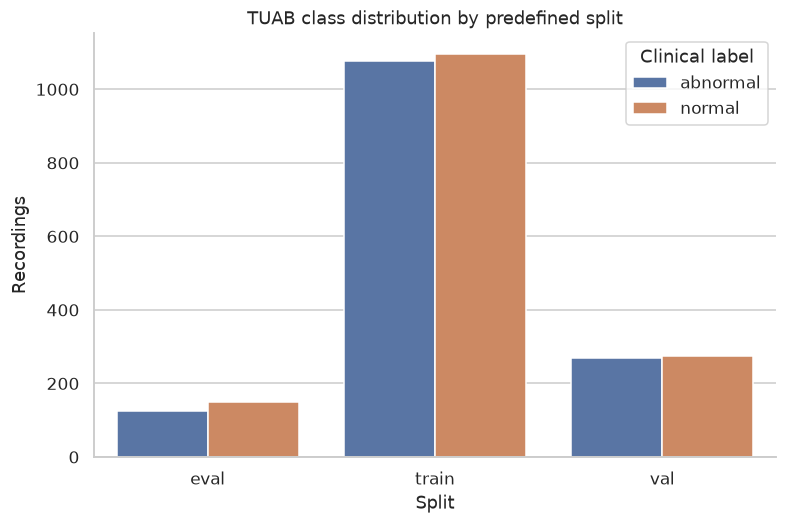

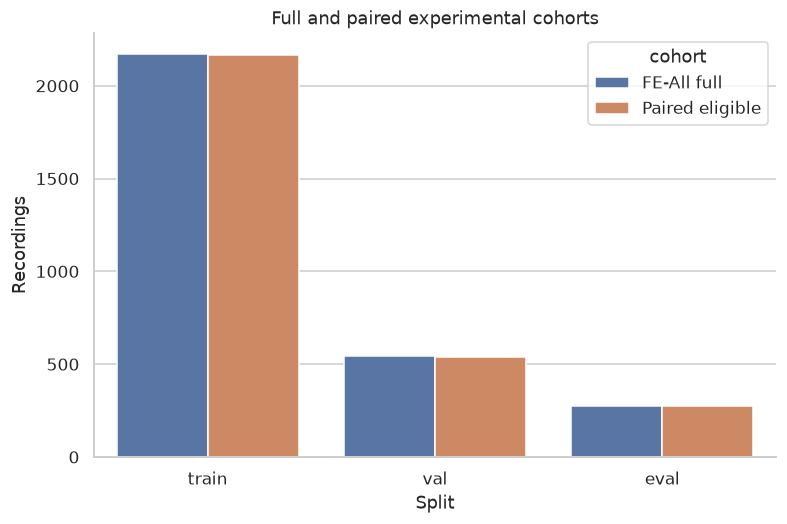

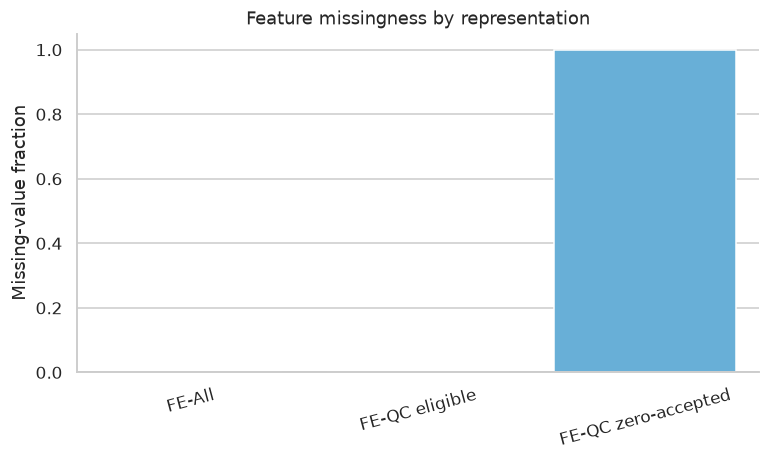

In [6]:
def save_figure(fig: plt.Figure, stem: str, final: bool = False) -> None:
    destination = OUTPUT_DIRS["final"] if final else FIGURE_DIR
    for suffix in ("png", "svg"):
        fig.savefig(destination / f"{RUN_ID}_{stem}.{suffix}", dpi=300, bbox_inches="tight")


class_counts = fe_all.groupby(["split", "label"]).size().rename("recordings").reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=class_counts, x="split", y="recordings", hue="label", ax=ax)
ax.set(title="TUAB class distribution by predefined split", xlabel="Split", ylabel="Recordings")
ax.legend(title="Clinical label")
save_figure(fig, "class_distribution_by_split")
plt.show()

cohort_counts = pd.DataFrame({
    "split": list(EXPECTED_ALL_COUNTS),
    "FE-All full": [EXPECTED_ALL_COUNTS[s] for s in EXPECTED_ALL_COUNTS],
    "Paired eligible": [EXPECTED_PAIRED_COUNTS[s] for s in EXPECTED_ALL_COUNTS],
}).melt("split", var_name="cohort", value_name="recordings")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=cohort_counts, x="split", y="recordings", hue="cohort", ax=ax)
ax.set(title="Full and paired experimental cohorts", xlabel="Split", ylabel="Recordings")
save_figure(fig, "full_vs_paired_counts")
plt.show()

missing_summary = pd.DataFrame({
    "dataset": ["FE-All", "FE-QC eligible", "FE-QC zero-accepted"],
    "missing_fraction": [
        fe_all[FEATURE_COLUMNS].isna().to_numpy().mean(),
        fe_qc.loc[qc_eligible_mask, FEATURE_COLUMNS].isna().to_numpy().mean(),
        fe_qc.loc[~qc_eligible_mask, FEATURE_COLUMNS].isna().to_numpy().mean(),
    ],
})
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=missing_summary, x="dataset", y="missing_fraction", color="#56B4E9", ax=ax)
ax.set(title="Feature missingness by representation", xlabel="", ylabel="Missing-value fraction", ylim=(0, 1.05))
ax.tick_params(axis="x", rotation=15)
save_figure(fig, "feature_missingness")
plt.show()

These diagnostic figures document class balance, cohort construction, and expected missingness before modelling. The paired cohort differs from the complete FE-All cohort only through FE-QC eligibility; cohort size differences must not be mistaken for model-performance differences.

## 7. Paired and full-cohort construction

In [7]:
eligible_ids = set(fe_qc.loc[qc_eligible_mask, "filepath"])
paired_all = fe_all.loc[fe_all["filepath"].isin(eligible_ids)].copy()
paired_qc = fe_qc.loc[fe_qc["filepath"].isin(eligible_ids)].copy()

paired_all = paired_all.sort_values("filepath").reset_index(drop=True)
paired_qc = paired_qc.sort_values("filepath").reset_index(drop=True)
full_all = fe_all.sort_values("filepath").reset_index(drop=True)

assert paired_all["filepath"].equals(paired_qc["filepath"])
assert paired_all["target"].equals(paired_qc["target"])
assert paired_all["patient_id"].equals(paired_qc["patient_id"])
assert paired_all["split"].equals(paired_qc["split"])
assert paired_all.groupby("split").size().to_dict() == EXPECTED_PAIRED_COUNTS
assert full_all.groupby("split").size().to_dict() == EXPECTED_ALL_COUNTS

COHORTS = {
    "paired_FE-All": paired_all,
    "paired_FE-QC": paired_qc,
    "full_FE-All": full_all,
}

for name, frame in COHORTS.items():
    print(name, len(frame), frame.groupby(["split", "label"]).size().to_dict())

paired_FE-All 2979 {('eval', 'abnormal'): 126, ('eval', 'normal'): 150, ('train', 'abnormal'): 1068, ('train', 'normal'): 1097, ('val', 'abnormal'): 266, ('val', 'normal'): 272}
paired_FE-QC 2979 {('eval', 'abnormal'): 126, ('eval', 'normal'): 150, ('train', 'abnormal'): 1068, ('train', 'normal'): 1097, ('val', 'abnormal'): 266, ('val', 'normal'): 272}
full_FE-All 2993 {('eval', 'abnormal'): 126, ('eval', 'normal'): 150, ('train', 'abnormal'): 1076, ('train', 'normal'): 1097, ('val', 'abnormal'): 270, ('val', 'normal'): 274}


## 8. Feature diagnostics (training data only)

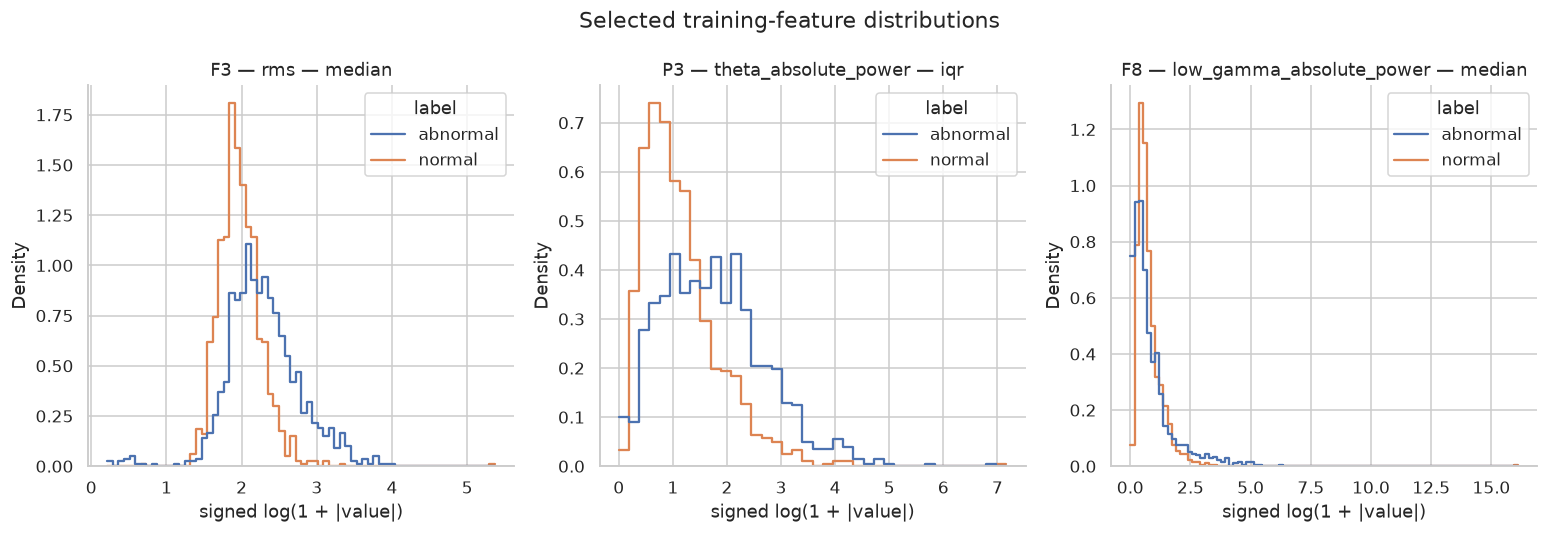

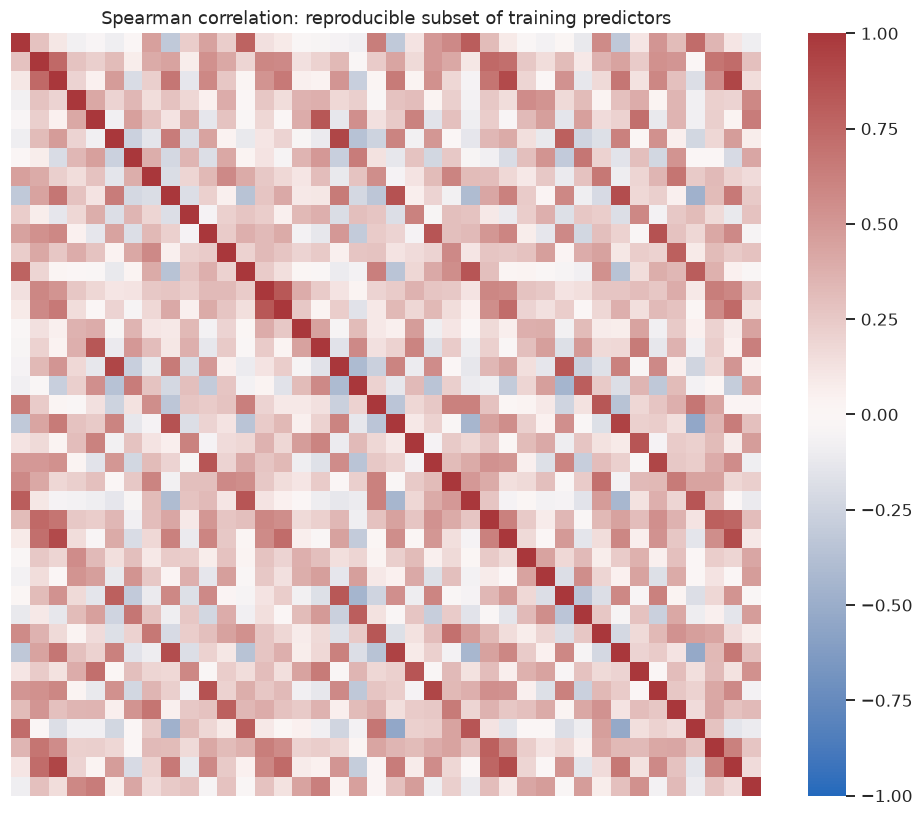

In [8]:
SELECTED_FEATURES = [
    "car__F3__rms__median",
    "car__P3__theta_absolute_power__iqr",
    "car__F8__low_gamma_absolute_power__median",
]
missing_selected = set(SELECTED_FEATURES) - set(FEATURE_COLUMNS)
assert not missing_selected, f"Missing diagnostic features: {sorted(missing_selected)}"

diagnostic = paired_all.loc[paired_all["split"].eq("train"), ["label", *SELECTED_FEATURES]].melt(
    id_vars="label", var_name="feature", value_name="value"
)
diagnostic["signed_log1p"] = np.sign(diagnostic["value"]) * np.log1p(np.abs(diagnostic["value"]))
fig, axes = plt.subplots(1, len(SELECTED_FEATURES), figsize=(17, 4.5))
for ax, feature in zip(axes, SELECTED_FEATURES):
    subset = diagnostic.loc[diagnostic["feature"].eq(feature)]
    sns.histplot(data=subset, x="signed_log1p", hue="label", stat="density", common_norm=False,
                 element="step", fill=False, ax=ax)
    ax.set_title(feature.replace("car__", "").replace("__", " — "))
    ax.set_xlabel("signed log(1 + |value|)")
fig.suptitle("Selected training-feature distributions", y=1.03)
save_figure(fig, "selected_training_feature_distributions")
plt.show()

# Correlation is intentionally limited to a reproducible feature subset for readability.
corr_features = FEATURE_COLUMNS[::max(1, len(FEATURE_COLUMNS) // 40)][:40]
train_corr = paired_all.loc[paired_all["split"].eq("train"), corr_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train_corr, cmap="vlag", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, ax=ax)
ax.set_title("Spearman correlation: reproducible subset of training predictors")
save_figure(fig, "training_feature_correlation")
plt.show()

Feature distributions are shown on a signed log scale only for visualization; the pipelines receive the original values. The correlation heatmap uses training data and a deterministic subset of predictors. Correlation indicates redundancy, not physiological interaction or causality.

## 9. Leakage-safe preprocessing pipelines and model definitions

In [9]:
def make_pipeline(model_name: str) -> Pipeline:
    common_imputer = ("imputer", SimpleImputer(strategy="median", add_indicator=True))
    if model_name == "Dummy":
        return Pipeline([common_imputer, ("classifier", DummyClassifier(strategy="prior", random_state=RANDOM_STATE))])
    if model_name == "Logistic Regression":
        return Pipeline([
            common_imputer,
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=5000, penalty="l2", solver="liblinear", random_state=RANDOM_STATE)),
        ])
    if model_name == "RBF SVM":
        return Pipeline([
            common_imputer,
            ("scaler", StandardScaler()),
            ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
        ])
    if model_name == "Random Forest":
        return Pipeline([
            common_imputer,
            ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, class_weight="balanced")),
        ])
    if model_name == "XGBoost":
        return Pipeline([
            common_imputer,
            ("classifier", XGBClassifier(
                objective="binary:logistic", eval_metric="logloss", random_state=RANDOM_STATE,
                n_jobs=1, tree_method="hist",
            )),
        ])
    raise KeyError(f"Unknown model: {model_name}")


PARAM_GRIDS = {
    "Dummy": {},
    "Logistic Regression": {"classifier__C": [0.01, 0.1, 1.0, 10.0]},
    "RBF SVM": {"classifier__C": [0.1, 1.0, 10.0], "classifier__gamma": ["scale", 0.001, 0.01]},
    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 3, 5],
    },
    "XGBoost": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [3, 5],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__subsample": [0.8, 1.0],
    },
}

MODEL_NAMES = list(PARAM_GRIDS)
for name in MODEL_NAMES:
    assert isinstance(make_pipeline(name), Pipeline)
print("Models:", MODEL_NAMES)
print("Total grid candidates:", {name: int(np.prod([len(v) for v in grid.values()])) if grid else 1 for name, grid in PARAM_GRIDS.items()})

Models: ['Dummy', 'Logistic Regression', 'RBF SVM', 'Random Forest', 'XGBoost']
Total grid candidates: {'Dummy': 1, 'Logistic Regression': 4, 'RBF SVM': 9, 'Random Forest': 18, 'XGBoost': 16}


Median imputation, scaling, and classifiers are enclosed in pipelines so every learned transformation is fitted separately inside each training fold. Tree estimators use one internal thread while the outer search controls parallelism, avoiding excessive nested parallelism on a 16-GB laptop.

## 10. Patient-grouped cross-validation

In [10]:
paired_train = paired_all.loc[paired_all["split"].eq("train")].reset_index(drop=True)
X_cv_reference = paired_train[FEATURE_COLUMNS]
y_cv_reference = paired_train["target"]
groups_cv_reference = paired_train["patient_id"]

cv_splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv_splitter.split(X_cv_reference, y_cv_reference, groups_cv_reference))

fold_audit = []
for fold, (train_idx, test_idx) in enumerate(CV_SPLITS, start=1):
    train_patients = set(groups_cv_reference.iloc[train_idx])
    test_patients = set(groups_cv_reference.iloc[test_idx])
    assert train_patients.isdisjoint(test_patients), f"Patient leakage in fold {fold}"
    fold_audit.append({
        "fold": fold,
        "train_recordings": len(train_idx),
        "test_recordings": len(test_idx),
        "train_patients": len(train_patients),
        "test_patients": len(test_patients),
        "test_abnormal_fraction": y_cv_reference.iloc[test_idx].mean(),
    })

fold_audit_df = pd.DataFrame(fold_audit)
display(fold_audit_df)
fold_audit_df.to_csv(OUTPUT_DIRS["cv"] / "fold_integrity.csv", index=False)

,fold,train_recordings,test_recordings,train_patients,test_patients,test_abnormal_fraction
0,1,1731,434,1325,337,0.493088
1,2,1731,434,1331,331,0.493088
2,3,1733,432,1332,330,0.493056
3,4,1733,432,1327,335,0.493056
4,5,1732,433,1333,329,0.494226


The same saved index partitions are reused for paired FE-All and FE-QC because their rows were explicitly sorted and matched by filepath. Each fold is patient-disjoint; stratification is approximate because grouping takes precedence over exact recording-level class balance.

## 11. Hyperparameter optimization

In [11]:
def run_grouped_searches(
    frame: pd.DataFrame,
    condition: str,
    cv_splits: list[tuple[np.ndarray, np.ndarray]],
) -> tuple[dict[str, GridSearchCV], pd.DataFrame, pd.DataFrame]:
    train = frame.loc[frame["split"].eq("train")].reset_index(drop=True)
    X = train[FEATURE_COLUMNS]
    y = train["target"]
    fitted_searches = {}
    candidate_tables = []
    fold_tables = []

    for model_name in MODEL_NAMES:
        print(f"[{condition}] searching {model_name} ...")
        scoring = {
            "roc_auc": "roc_auc",
            "balanced_accuracy": "balanced_accuracy",
            "sensitivity": make_scorer(recall_score, pos_label=1, zero_division=0),
            "specificity": make_scorer(recall_score, pos_label=0, zero_division=0),
            "precision": make_scorer(precision_score, zero_division=0),
            "f1": "f1",
        }
        search = GridSearchCV(
            estimator=make_pipeline(model_name),
            param_grid=PARAM_GRIDS[model_name],
            scoring=scoring,
            cv=cv_splits,
            n_jobs=N_JOBS,
            refit="roc_auc",
            return_train_score=False,
            error_score="raise",
        )
        started = time.perf_counter()
        search.fit(X, y)
        elapsed = time.perf_counter() - started
        fitted_searches[model_name] = search

        result = pd.DataFrame(search.cv_results_)
        result.insert(0, "condition", condition)
        result.insert(1, "model", model_name)
        result["elapsed_seconds"] = elapsed
        candidate_tables.append(result)

        best_row = result.loc[search.best_index_]
        for fold in range(N_SPLITS):
            fold_row = {
                "condition": condition,
                "model": model_name,
                "fold": fold + 1,
                "best_params": json.dumps(search.best_params_, sort_keys=True),
            }
            for metric in scoring:
                fold_row[metric] = best_row[f"split{fold}_test_{metric}"]
            fold_tables.append(fold_row)

        safe_name = model_name.lower().replace(" ", "_")
        result.to_csv(OUTPUT_DIRS["cv"] / f"{condition}_{safe_name}_grid.csv", index=False)
        joblib.dump(search.best_estimator_, OUTPUT_DIRS["models"] / f"{condition}_{safe_name}.joblib")

    return fitted_searches, pd.concat(candidate_tables, ignore_index=True), pd.DataFrame(fold_tables)


# Primary paired experiment. These calls train models and can take substantial time.
searches_all, grid_all, folds_all = run_grouped_searches(paired_all, "FE-All", CV_SPLITS)
searches_qc, grid_qc, folds_qc = run_grouped_searches(paired_qc, "FE-QC", CV_SPLITS)

grid_results = pd.concat([grid_all, grid_qc], ignore_index=True)
fold_results = pd.concat([folds_all, folds_qc], ignore_index=True)
grid_results.to_csv(OUTPUT_DIRS["cv"] / "all_hyperparameter_results.csv", index=False)
fold_results.to_csv(OUTPUT_DIRS["cv"] / "best_candidate_fold_scores.csv", index=False)

best_summary = (
    fold_results.groupby(["condition", "model"], as_index=False)
    .agg(mean_roc_auc=("roc_auc", "mean"), sd_roc_auc=("roc_auc", "std"))
)
display(best_summary.sort_values(["condition", "mean_roc_auc"], ascending=[True, False]))

[FE-All] searching Dummy ...
[FE-All] searching Logistic Regression ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

[FE-All] searching RBF SVM ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


[FE-All] searching Random Forest ...
[FE-All] searching XGBoost ...
[FE-QC] searching Dummy ...
[FE-QC] searching Logistic Regression ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

[FE-QC] searching RBF SVM ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


[FE-QC] searching Random Forest ...
[FE-QC] searching XGBoost ...


,condition,model,mean_roc_auc,sd_roc_auc
4,FE-All,XGBoost,0.921897,0.010343
2,FE-All,RBF SVM,0.910270,0.011709
3,FE-All,Random Forest,0.907195,0.015345
1,FE-All,Logistic Regression,0.901776,0.018774
0,FE-All,Dummy,0.500000,0.000000
9,FE-QC,XGBoost,0.920994,0.015439
7,FE-QC,RBF SVM,0.914698,0.008799
6,FE-QC,Logistic Regression,0.910178,0.017283
8,FE-QC,Random Forest,0.908956,0.016737
5,FE-QC,Dummy,0.500000,0.000000


## 12. Cross-validation visualization

/tmp/ipykernel_382642/2208132220.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=fold_results, x="model", y="roc_auc", hue="condition", dodge=True,


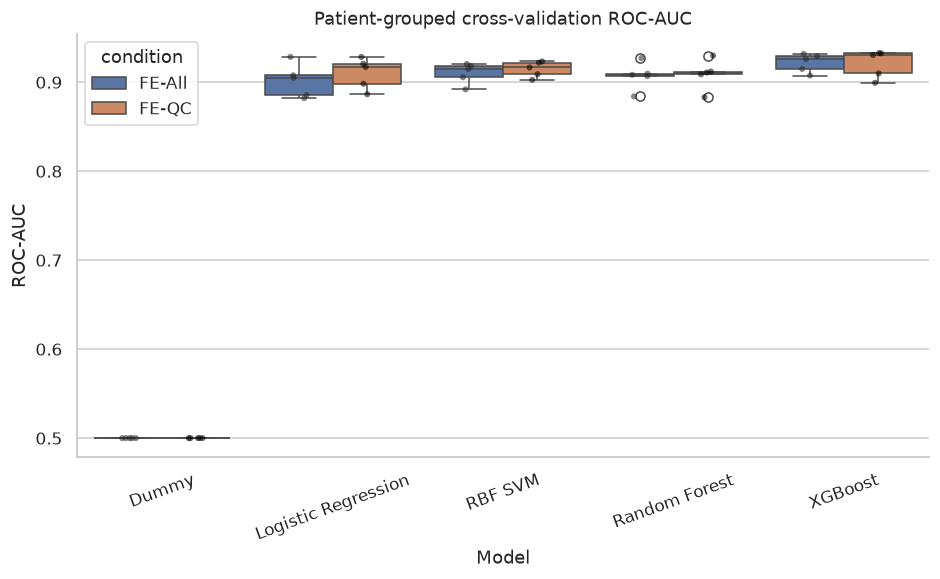

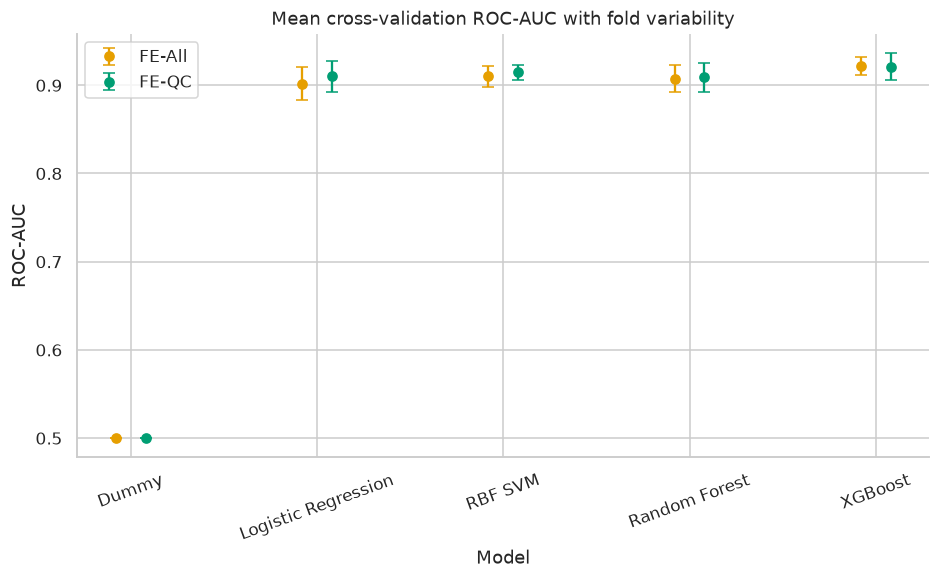

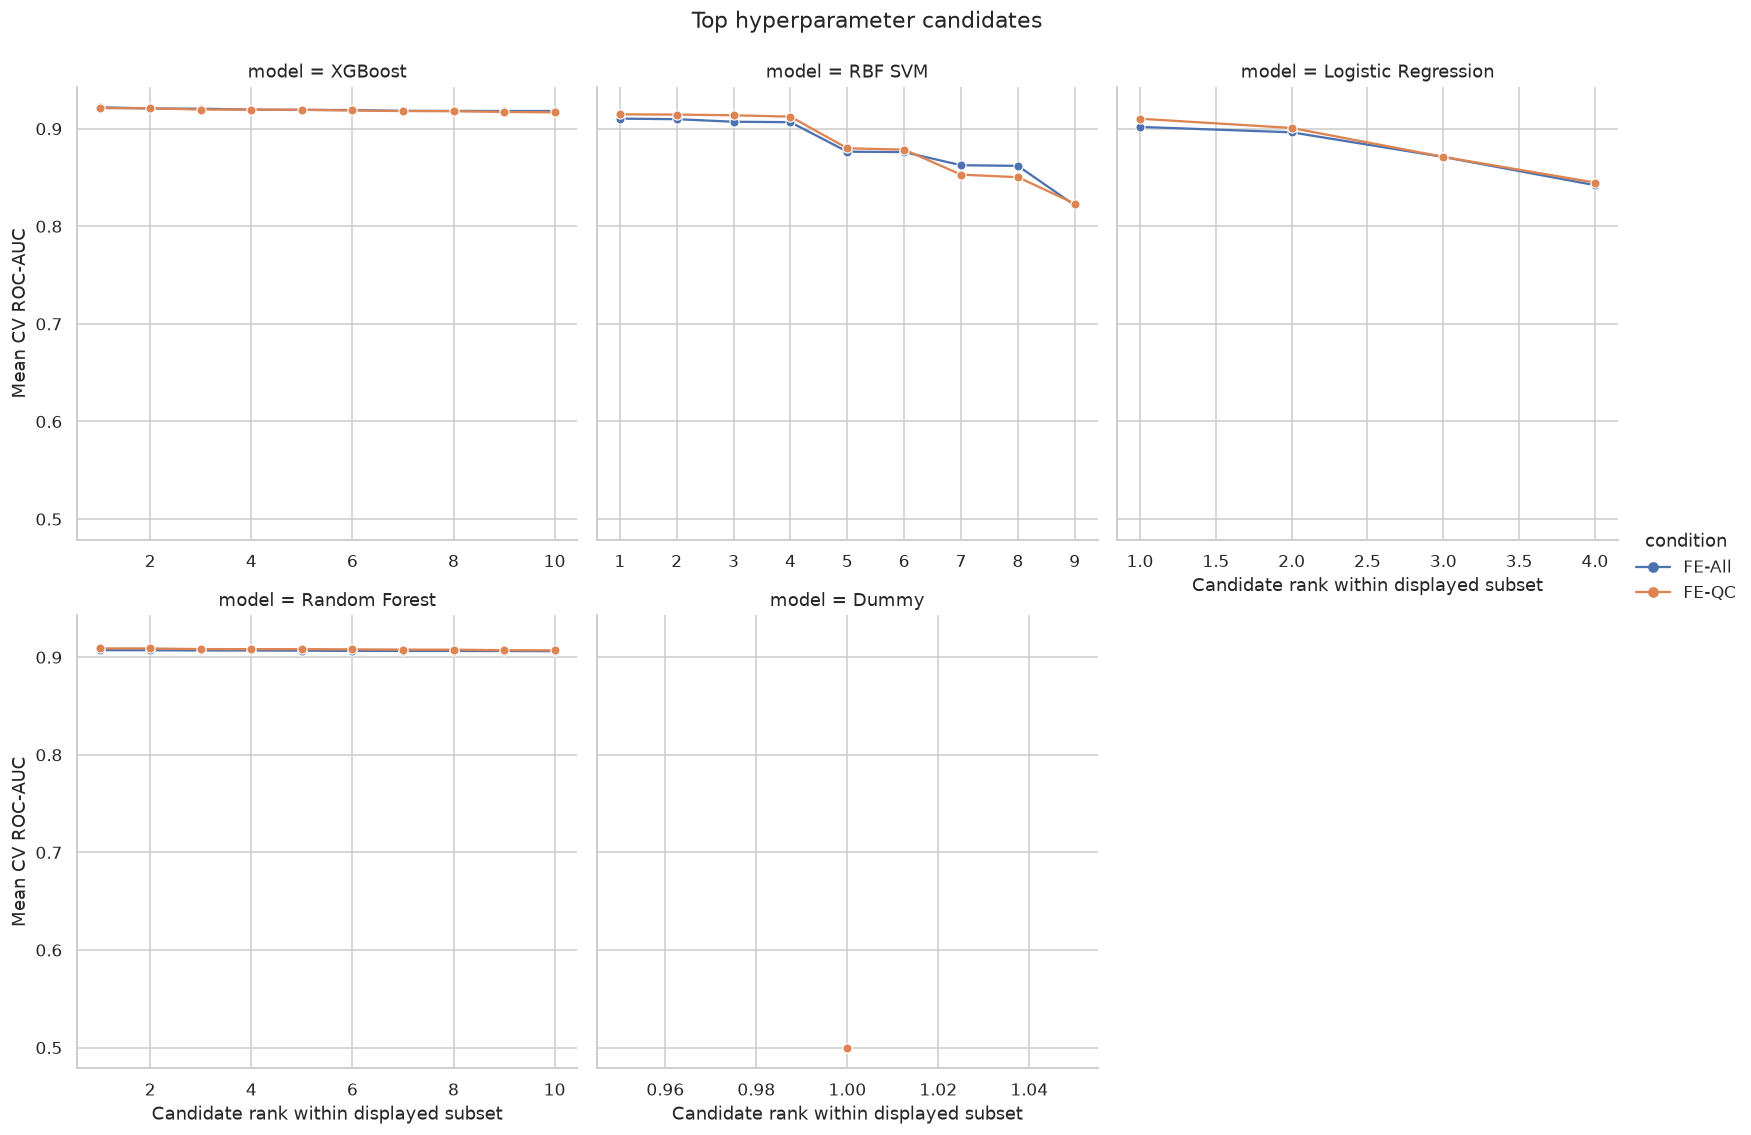

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=fold_results, x="model", y="roc_auc", hue="condition", ax=ax)
sns.stripplot(data=fold_results, x="model", y="roc_auc", hue="condition", dodge=True,
              color="black", alpha=0.55, size=4, legend=False, ax=ax)
ax.set(title="Patient-grouped cross-validation ROC-AUC", xlabel="Model", ylabel="ROC-AUC")
ax.tick_params(axis="x", rotation=20)
save_figure(fig, "cv_fold_roc_auc")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for condition, offset in [("FE-All", -0.08), ("FE-QC", 0.08)]:
    subset = best_summary.loc[best_summary["condition"].eq(condition)].set_index("model").reindex(MODEL_NAMES)
    x = np.arange(len(MODEL_NAMES)) + offset
    ax.errorbar(x, subset["mean_roc_auc"], yerr=subset["sd_roc_auc"], fmt="o", capsize=4,
                label=condition, color=CONDITION_COLORS[condition])
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES, rotation=20)
ax.set(title="Mean cross-validation ROC-AUC with fold variability", xlabel="Model", ylabel="ROC-AUC")
ax.legend()
save_figure(fig, "cv_model_comparison_errorbars")
plt.show()

# Hyperparameter landscape: top candidates per model and condition.
top_candidates = (
    grid_results.sort_values("mean_test_roc_auc", ascending=False)
    .groupby(["condition", "model"], as_index=False, group_keys=False).head(10)
    .assign(candidate=lambda d: d.groupby(["condition", "model"]).cumcount() + 1)
)
g = sns.relplot(data=top_candidates, x="candidate", y="mean_test_roc_auc", hue="condition",
                col="model", col_wrap=3, kind="line", marker="o", facet_kws={"sharex": False})
g.set_axis_labels("Candidate rank within displayed subset", "Mean CV ROC-AUC")
g.fig.suptitle("Top hyperparameter candidates", y=1.03)
save_figure(g.fig, "hyperparameter_search_top_candidates")
plt.show()

Cross-validation plots compare identical patient-grouped folds across FE-All and FE-QC. Error bars describe variation across five folds, not confidence intervals for population performance. Hyperparameter plots summarize searched candidates and must not be interpreted as independent repeated experiments.

## 13. Validation evaluation and threshold calibration

In [13]:
def positive_probability(estimator: Pipeline, X: pd.DataFrame) -> np.ndarray:
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    scores = estimator.decision_function(X)
    return 1.0 / (1.0 + np.exp(-scores))


def select_youden_threshold(y_true: np.ndarray, probability: np.ndarray) -> float:
    fpr, tpr, thresholds = roc_curve(y_true, probability)
    finite = np.isfinite(thresholds)
    index = np.argmax((tpr - fpr)[finite])
    return float(thresholds[finite][index])


def binary_metrics(y_true: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y_true, probability),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "precision": precision_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "threshold": threshold,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }


def validation_predictions(frame: pd.DataFrame, searches: dict, condition: str):
    validation = frame.loc[frame["split"].eq("val")].reset_index(drop=True)
    X_val, y_val = validation[FEATURE_COLUMNS], validation["target"].to_numpy()
    prediction_tables, metric_rows, thresholds = [], [], {}
    for model_name, search in searches.items():
        probability = positive_probability(search.best_estimator_, X_val)
        threshold = select_youden_threshold(y_val, probability)
        thresholds[model_name] = threshold
        metric_rows.append({"condition": condition, "model": model_name, **binary_metrics(y_val, probability, threshold)})
        prediction_tables.append(pd.DataFrame({
            "filepath": validation["filepath"], "patient_id": validation["patient_id"],
            "label": validation["label"], "target": y_val, "split": "val",
            "condition": condition, "model": model_name, "probability": probability,
            "prediction": (probability >= threshold).astype(int), "threshold": threshold,
        }))
    return pd.concat(prediction_tables, ignore_index=True), pd.DataFrame(metric_rows), thresholds


val_pred_all, val_metrics_all, thresholds_all = validation_predictions(paired_all, searches_all, "FE-All")
val_pred_qc, val_metrics_qc, thresholds_qc = validation_predictions(paired_qc, searches_qc, "FE-QC")
validation_predictions_df = pd.concat([val_pred_all, val_pred_qc], ignore_index=True)
validation_metrics_df = pd.concat([val_metrics_all, val_metrics_qc], ignore_index=True)

validation_predictions_df.to_parquet(OUTPUT_DIRS["validation"] / "recording_predictions.parquet", index=False)
validation_metrics_df.to_csv(OUTPUT_DIRS["validation"] / "metrics.csv", index=False)
display(validation_metrics_df.sort_values(["condition", "roc_auc"], ascending=[True, False]))

,condition,model,roc_auc,balanced_accuracy,sensitivity,specificity,precision,f1,threshold,tn,fp,fn,tp
2,FE-All,RBF SVM,0.907936,0.830274,0.778195,0.882353,0.866109,0.819802,0.551502,240,32,59,207
4,FE-All,XGBoost,0.906291,0.831781,0.748120,0.915441,0.896396,0.815574,0.574254,249,23,67,199
1,FE-All,Logistic Regression,0.904149,0.838000,0.812030,0.863971,0.853755,0.832370,0.448041,235,37,50,216
3,FE-All,Random Forest,0.893949,0.828270,0.763158,0.893382,0.875000,0.815261,0.502587,243,29,63,203
0,FE-All,Dummy,0.500000,0.500000,1.000000,0.000000,0.494424,0.661692,0.493303,0,272,0,266
7,FE-QC,RBF SVM,0.918330,0.839134,0.748120,0.930147,0.912844,0.822314,0.658791,253,19,67,199
9,FE-QC,XGBoost,0.904771,0.825299,0.827068,0.823529,0.820896,0.823970,0.353455,224,48,46,220
8,FE-QC,Random Forest,0.898040,0.839756,0.804511,0.875000,0.862903,0.832685,0.482486,238,34,52,214
6,FE-QC,Logistic Regression,0.861787,0.824220,0.729323,0.919118,0.898148,0.804979,0.543802,250,22,72,194
5,FE-QC,Dummy,0.500000,0.500000,1.000000,0.000000,0.494424,0.661692,0.493303,0,272,0,266


Validation ROC-AUC is threshold-independent. The remaining metrics use a Youden-index threshold selected on validation data and are therefore development estimates, not unbiased final-performance estimates. Evaluation labels are not accessed in this section.

## 14. ROC, precision–recall, confusion-matrix, and metric visualizations

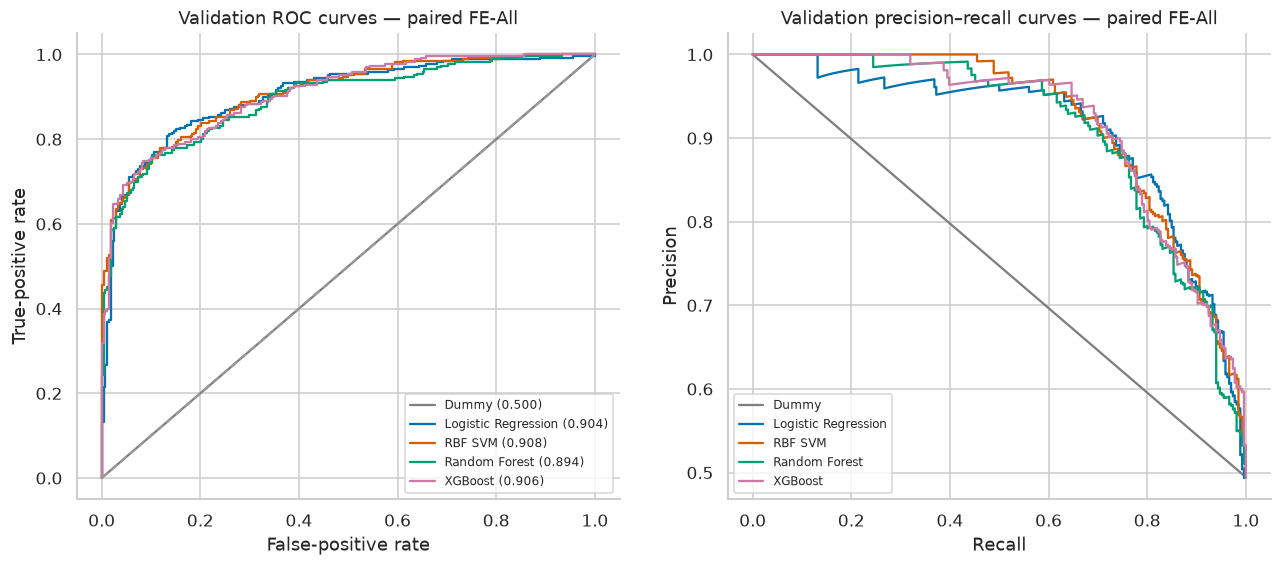

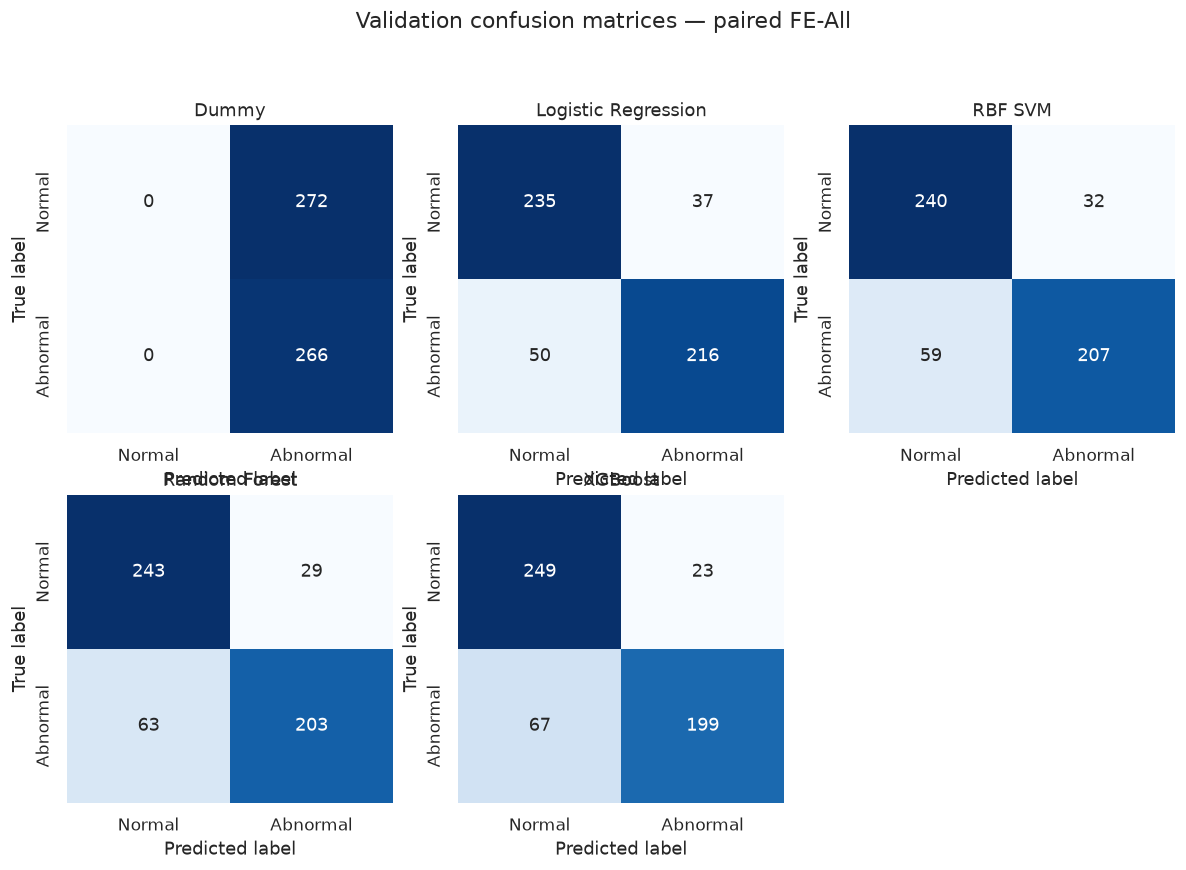

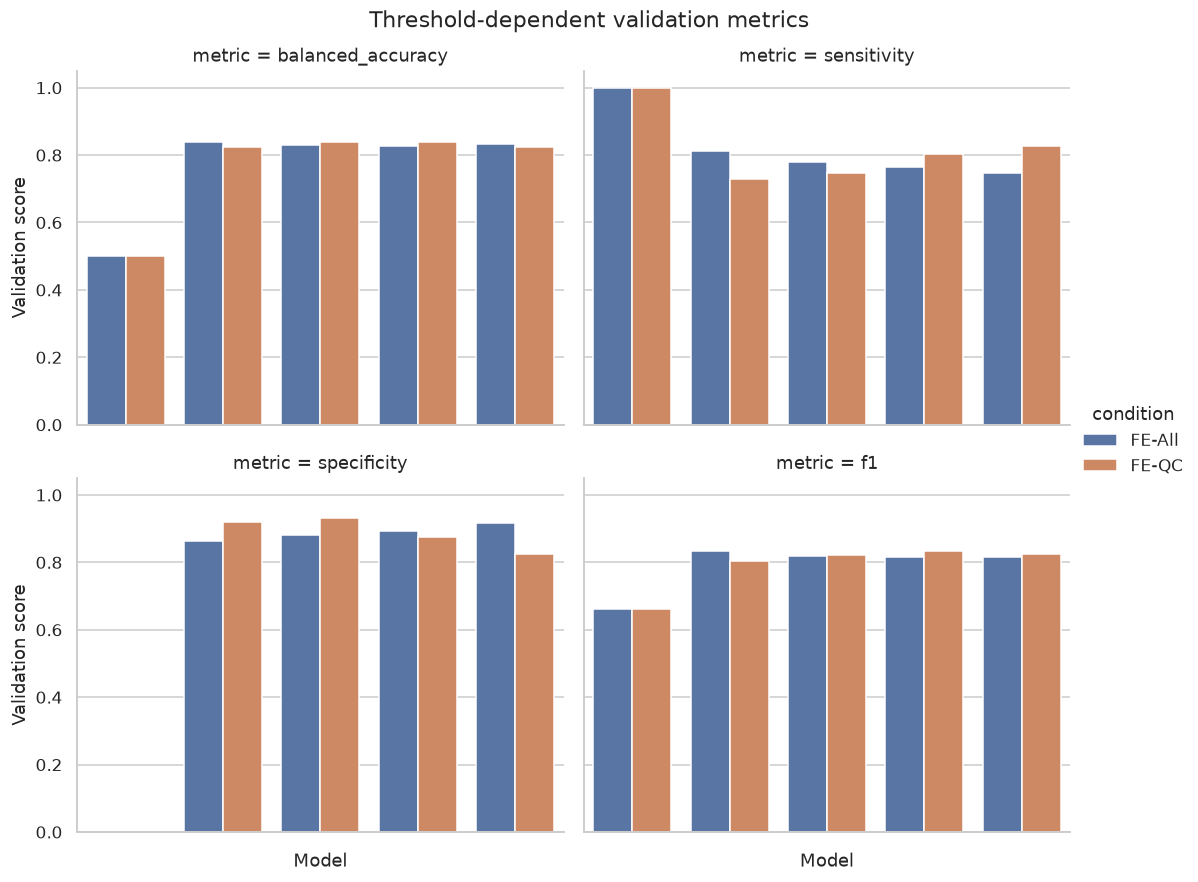

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for model_name in MODEL_NAMES:
    subset = val_pred_all.loc[val_pred_all["model"].eq(model_name)]
    fpr, tpr, _ = roc_curve(subset["target"], subset["probability"])
    auc = roc_auc_score(subset["target"], subset["probability"])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[model_name], label=f"{model_name} ({auc:.3f})")
    precision, recall, _ = precision_recall_curve(subset["target"], subset["probability"])
    axes[1].plot(recall, precision, color=MODEL_COLORS[model_name], label=model_name)
axes[0].plot([0, 1], [0, 1], "--", color="0.6")
axes[0].set(title="Validation ROC curves — paired FE-All", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].set(title="Validation precision–recall curves — paired FE-All", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8)
save_figure(fig, "validation_roc_pr_fe_all")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    row = validation_metrics_df.query("condition == 'FE-All' and model == @model_name").iloc[0]
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=int)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=model_name, xlabel="Predicted label", ylabel="True label", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
axes.flat[-1].axis("off")
fig.suptitle("Validation confusion matrices — paired FE-All", y=1.01)
save_figure(fig, "validation_confusion_matrices_fe_all")
plt.show()

metric_long = validation_metrics_df.melt(
    id_vars=["condition", "model"], value_vars=["balanced_accuracy", "sensitivity", "specificity", "f1"],
    var_name="metric", value_name="score"
)
g = sns.catplot(data=metric_long, x="model", y="score", hue="condition", col="metric",
                kind="bar", col_wrap=2, height=4, aspect=1.25)
g.set_xticklabels(rotation=25)
g.set_axis_labels("Model", "Validation score")
g.fig.suptitle("Threshold-dependent validation metrics", y=1.02)
save_figure(g.fig, "validation_secondary_metrics")
plt.show()

These figures describe the paired validation cohort. ROC and precision–recall curves evaluate ranking; confusion matrices and secondary metrics depend on validation-calibrated thresholds. Comparisons are exploratory until the locked evaluation is run, and multiple models share the same validation cases.

## 15. Patient-level aggregation and clustered uncertainty

In [15]:
def audit_patient_labels(predictions: pd.DataFrame) -> pd.DataFrame:
    # Remove repeated model/condition rows before auditing recording labels.
    recordings = predictions[["filepath", "patient_id", "target", "label"]].drop_duplicates()
    audit = (
        recordings.groupby("patient_id", as_index=False)
        .agg(
            recordings=("filepath", "nunique"),
            distinct_targets=("target", "nunique"),
            observed_labels=("label", lambda values: " | ".join(sorted(set(map(str, values))))),
        )
        .assign(label_consistent=lambda frame: frame["distinct_targets"].eq(1))
    )
    return audit


def patient_cluster_bootstrap_auc(
    predictions: pd.DataFrame,
    n_boot: int = 2000,
    seed: int = RANDOM_STATE,
) -> tuple[float, float]:
    """Recording-level ROC-AUC CI from a patient-cluster bootstrap.

    Whole patient clusters are sampled with replacement, retaining every recording
    and its recording-level target. This remains valid when one patient has both
    normal and abnormal recordings.
    """
    rng = np.random.default_rng(seed)
    patients = predictions["patient_id"].unique()
    grouped = {patient: group for patient, group in predictions.groupby("patient_id", sort=False)}
    estimates = []
    for _ in range(n_boot):
        sampled = rng.choice(patients, size=len(patients), replace=True)
        bootstrap = pd.concat([grouped[patient] for patient in sampled], ignore_index=True)
        if bootstrap["target"].nunique() == 2:
            estimates.append(roc_auc_score(bootstrap["target"], bootstrap["probability"]))
    if not estimates:
        raise RuntimeError("No valid two-class patient-cluster bootstrap samples were produced.")
    return tuple(np.quantile(estimates, [0.025, 0.975]))


patient_label_audit = audit_patient_labels(validation_predictions_df)
inconsistent_patients = patient_label_audit.loc[~patient_label_audit["label_consistent"]].copy()
print("Validation patients:", len(patient_label_audit))
print("Patients with recordings from both classes:", len(inconsistent_patients))
display(inconsistent_patients)
patient_label_audit.to_csv(
    OUTPUT_DIRS["validation"] / "patient_label_consistency_audit.csv", index=False
)

# A single patient-level target is scientifically undefined for inconsistent patients.
# Report recording-level metrics with patient-clustered ROC-AUC confidence intervals instead.
clustered_metric_rows = []
for (condition, model), group in validation_predictions_df.groupby(["condition", "model"]):
    threshold = float(group["threshold"].iloc[0])
    low, high = patient_cluster_bootstrap_auc(group)
    clustered_metric_rows.append({
        "condition": condition,
        "model": model,
        **binary_metrics(group["target"].to_numpy(), group["probability"].to_numpy(), threshold),
        "roc_auc_ci_low": low,
        "roc_auc_ci_high": high,
        "recordings": group["filepath"].nunique(),
        "patients": group["patient_id"].nunique(),
        "estimand": "recording_level_with_patient_clustered_ci",
    })

clustered_validation_metrics_df = pd.DataFrame(clustered_metric_rows)
display(clustered_validation_metrics_df)
clustered_validation_metrics_df.to_csv(
    OUTPUT_DIRS["validation"] / "recording_metrics_patient_clustered_ci.csv", index=False
)


Validation patients: 410
Patients with recordings from both classes: 12


,patient_id,recordings,distinct_targets,observed_labels,label_consistent
9,aaaaabhz,4,2,abnormal | normal,False
19,aaaaadnb,3,2,abnormal | normal,False
30,aaaaaffn,3,2,abnormal | normal,False
59,aaaaaizb,6,2,abnormal | normal,False
65,aaaaajgj,2,2,abnormal | normal,False
67,aaaaajns,2,2,abnormal | normal,False
156,aaaaalqm,2,2,abnormal | normal,False
168,aaaaalzq,2,2,abnormal | normal,False
196,aaaaammb,2,2,abnormal | normal,False
201,aaaaamni,2,2,abnormal | normal,False


,condition,model,roc_auc,balanced_accuracy,sensitivity,specificity,precision,f1,threshold,tn,fp,fn,tp,roc_auc_ci_low,roc_auc_ci_high,recordings,patients,estimand
0,FE-All,Dummy,0.500000,0.500000,1.000000,0.000000,0.494424,0.661692,0.493303,0,272,0,266,0.500000,0.500000,538,410,recording_level_with_patient_clustered_ci
1,FE-All,Logistic Regression,0.904149,0.838000,0.812030,0.863971,0.853755,0.832370,0.448041,235,37,50,216,0.875112,0.929994,538,410,recording_level_with_patient_clustered_ci
2,FE-All,RBF SVM,0.907936,0.830274,0.778195,0.882353,0.866109,0.819802,0.551502,240,32,59,207,0.880153,0.932438,538,410,recording_level_with_patient_clustered_ci
3,FE-All,Random Forest,0.893949,0.828270,0.763158,0.893382,0.875000,0.815261,0.502587,243,29,63,203,0.862900,0.923545,538,410,recording_level_with_patient_clustered_ci
4,FE-All,XGBoost,0.906291,0.831781,0.748120,0.915441,0.896396,0.815574,0.574254,249,23,67,199,0.878975,0.932356,538,410,recording_level_with_patient_clustered_ci
5,FE-QC,Dummy,0.500000,0.500000,1.000000,0.000000,0.494424,0.661692,0.493303,0,272,0,266,0.500000,0.500000,538,410,recording_level_with_patient_clustered_ci
6,FE-QC,Logistic Regression,0.861787,0.824220,0.729323,0.919118,0.898148,0.804979,0.543802,250,22,72,194,0.819626,0.901253,538,410,recording_level_with_patient_clustered_ci
7,FE-QC,RBF SVM,0.918330,0.839134,0.748120,0.930147,0.912844,0.822314,0.658791,253,19,67,199,0.892061,0.941669,538,410,recording_level_with_patient_clustered_ci
8,FE-QC,Random Forest,0.898040,0.839756,0.804511,0.875000,0.862903,0.832685,0.482486,238,34,52,214,0.868046,0.926668,538,410,recording_level_with_patient_clustered_ci
9,FE-QC,XGBoost,0.904771,0.825299,0.827068,0.823529,0.820896,0.823970,0.353455,224,48,46,220,0.875594,0.931194,538,410,recording_level_with_patient_clustered_ci


Patient-level probability aggregation is not reported because some TUAB patients have both normal and abnormal recording labels, so a unique patient-level target is undefined. Performance remains recording-level, while confidence intervals resample whole patients to preserve dependence among recordings from the same patient. The label-consistency audit is exported for transparent reporting.

## 16. FE-All versus FE-QC paired comparison

,model,roc_auc_all,roc_auc_qc,roc_auc_difference_qc_minus_all,balanced_accuracy_all,balanced_accuracy_qc,balanced_accuracy_difference_qc_minus_all
0,Dummy,0.500000,0.500000,0.000000,0.500000,0.500000,0.000000
1,Logistic Regression,0.904149,0.861787,-0.042362,0.838000,0.824220,-0.013780
2,RBF SVM,0.907936,0.918330,0.010394,0.830274,0.839134,0.008859
3,Random Forest,0.893949,0.898040,0.004091,0.828270,0.839756,0.011486
4,XGBoost,0.906291,0.904771,-0.001520,0.831781,0.825299,-0.006482


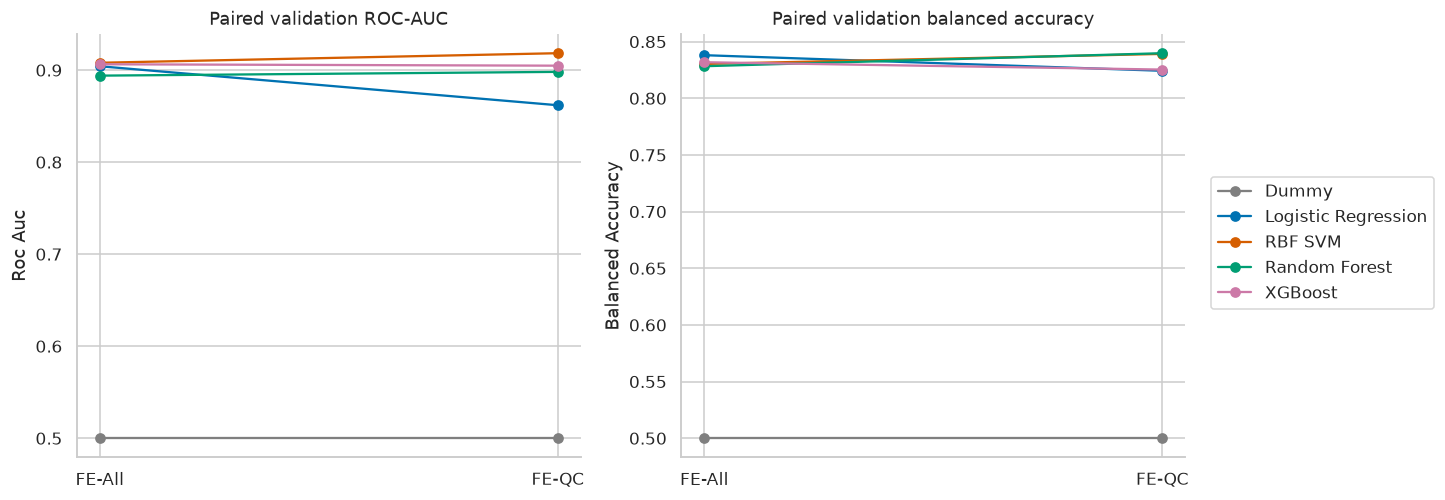

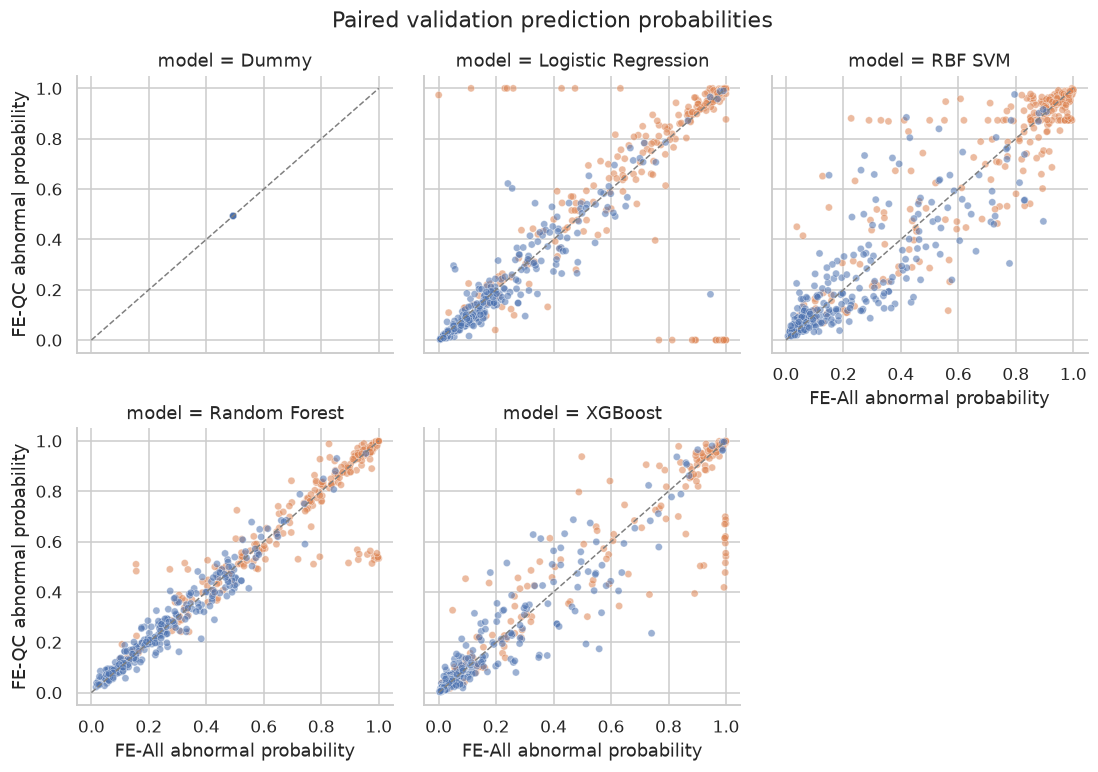

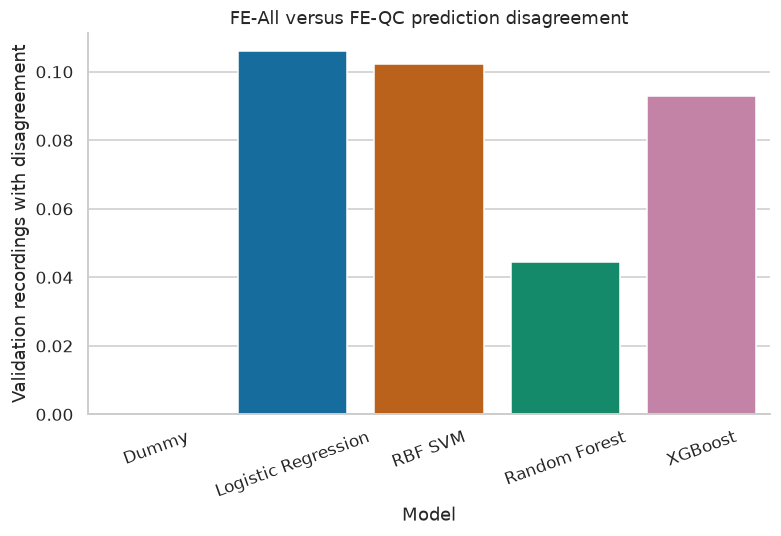

In [16]:
paired_validation_predictions = val_pred_all.merge(
    val_pred_qc,
    on=["filepath", "patient_id", "label", "target", "split", "model"],
    suffixes=("_all", "_qc"),
    validate="one_to_one",
)
paired_validation_predictions["probability_difference_qc_minus_all"] = (
    paired_validation_predictions["probability_qc"] - paired_validation_predictions["probability_all"]
)
paired_validation_predictions["prediction_disagreement"] = (
    paired_validation_predictions["prediction_all"] != paired_validation_predictions["prediction_qc"]
)

metric_pair = val_metrics_all.merge(val_metrics_qc, on="model", suffixes=("_all", "_qc"), validate="one_to_one")
for metric in ["roc_auc", "balanced_accuracy"]:
    metric_pair[f"{metric}_difference_qc_minus_all"] = metric_pair[f"{metric}_qc"] - metric_pair[f"{metric}_all"]
display(metric_pair[["model", "roc_auc_all", "roc_auc_qc", "roc_auc_difference_qc_minus_all",
                     "balanced_accuracy_all", "balanced_accuracy_qc", "balanced_accuracy_difference_qc_minus_all"]])
metric_pair.to_csv(OUTPUT_DIRS["comparisons"] / "paired_validation_metric_differences.csv", index=False)
paired_validation_predictions.to_parquet(OUTPUT_DIRS["comparisons"] / "paired_validation_predictions.parquet", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in [
    (axes[0], "roc_auc", "Paired validation ROC-AUC"),
    (axes[1], "balanced_accuracy", "Paired validation balanced accuracy"),
]:
    for _, row in metric_pair.iterrows():
        ax.plot([0, 1], [row[f"{metric}_all"], row[f"{metric}_qc"]], marker="o",
                color=MODEL_COLORS[row["model"]], label=row["model"])
    ax.set_xticks([0, 1], ["FE-All", "FE-QC"])
    ax.set(title=title, ylabel=metric.replace("_", " ").title())
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", bbox_to_anchor=(1.08, 0.5))
save_figure(fig, "paired_validation_metric_changes")
plt.show()

g = sns.FacetGrid(paired_validation_predictions, col="model", col_wrap=3, height=3.4)
g.map_dataframe(sns.scatterplot, x="probability_all", y="probability_qc", hue="target", alpha=0.55, s=22)
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], "--", color="0.5", linewidth=1)
g.set_axis_labels("FE-All abnormal probability", "FE-QC abnormal probability")
g.fig.suptitle("Paired validation prediction probabilities", y=1.03)
save_figure(g.fig, "paired_probability_scatter")
plt.show()

disagreement = paired_validation_predictions.groupby("model")["prediction_disagreement"].mean().rename("fraction").reset_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=disagreement, x="model", y="fraction", palette=MODEL_COLORS, hue="model", legend=False, ax=ax)
ax.set(title="FE-All versus FE-QC prediction disagreement", xlabel="Model", ylabel="Validation recordings with disagreement")
ax.tick_params(axis="x", rotation=20)
save_figure(fig, "paired_prediction_disagreement")
plt.show()

Every FE-All/FE-QC comparison uses the same recording identifiers. Connecting lines show the direction of model-level changes but do not provide inferential significance. Probability scatterplots and disagreement rates reveal whether QC changes individual decisions even when aggregate metrics are similar.

## 17. QC coverage sensitivity analysis

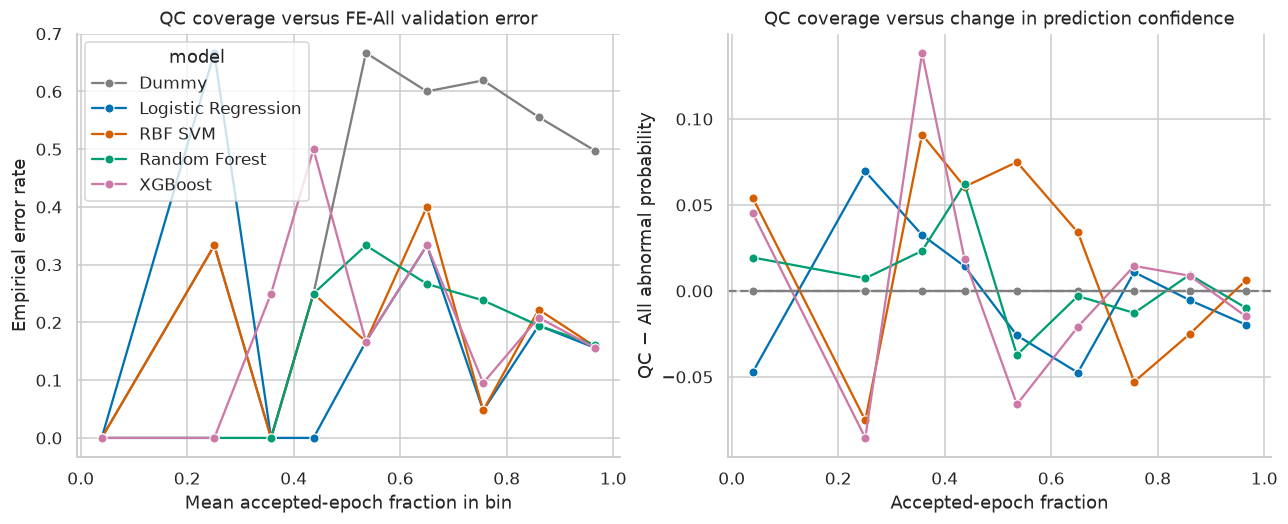

,model,coverage_group,recordings,error_rate_all,error_rate_qc
0,Dummy,≤25%,5,0.200000,0.200000
1,Dummy,>25–50%,9,0.111111,0.111111
2,Dummy,>50–75%,29,0.620690,0.620690
3,Dummy,>75–90%,85,0.564706,0.564706
4,Dummy,>90–100%,410,0.497561,0.497561
5,Logistic Regression,≤25%,5,0.400000,0.000000
6,Logistic Regression,>25–50%,9,0.000000,0.000000
7,Logistic Regression,>50–75%,29,0.241379,0.344828
8,Logistic Regression,>75–90%,85,0.164706,0.164706
9,Logistic Regression,>90–100%,410,0.156098,0.170732


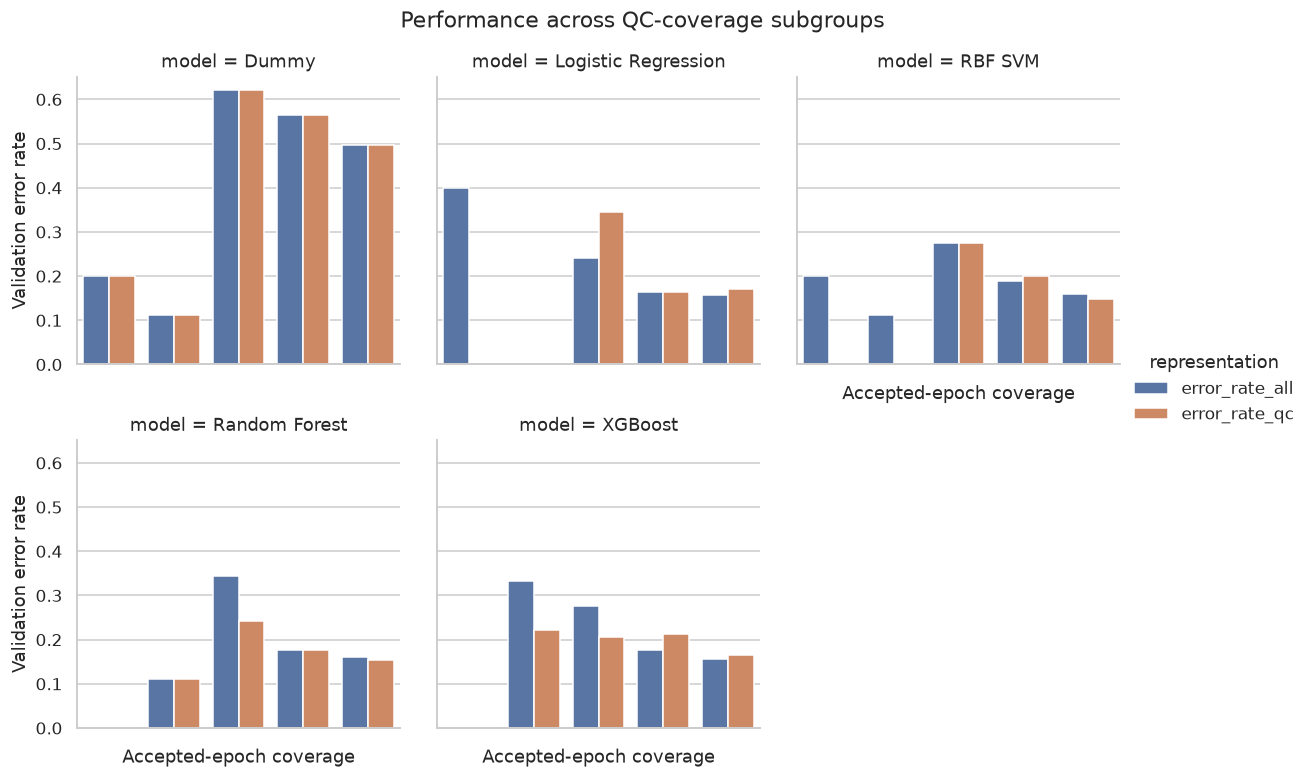

In [17]:
coverage = paired_qc[["filepath", *QC_COLUMNS]].copy()
qc_analysis = paired_validation_predictions.merge(coverage, on="filepath", validate="many_to_one")
qc_analysis["error_all"] = qc_analysis["prediction_all"].ne(qc_analysis["target"])
qc_analysis["error_qc"] = qc_analysis["prediction_qc"].ne(qc_analysis["target"])
qc_analysis["coverage_group"] = pd.cut(
    qc_analysis["accepted_fraction"], bins=[-np.inf, 0.25, 0.50, 0.75, 0.90, 1.0],
    labels=["≤25%", ">25–50%", ">50–75%", ">75–90%", ">90–100%"], include_lowest=True,
)

# Use empirical coverage bins rather than seaborn's optional statsmodels logistic fit.
qc_analysis["coverage_decile"] = pd.cut(
    qc_analysis["accepted_fraction"], bins=np.linspace(0, 1, 11), include_lowest=True
)
coverage_curve = (
    qc_analysis.groupby(["model", "coverage_decile"], observed=True)
    .agg(
        mean_coverage=("accepted_fraction", "mean"),
        error_rate_all=("error_all", "mean"),
        mean_probability_change=("probability_difference_qc_minus_all", "mean"),
        recordings=("filepath", "nunique"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(
    data=coverage_curve, x="mean_coverage", y="error_rate_all", hue="model",
    marker="o", palette=MODEL_COLORS, ax=axes[0],
)
axes[0].set(title="QC coverage versus FE-All validation error", xlabel="Mean accepted-epoch fraction in bin", ylabel="Empirical error rate")
sns.lineplot(
    data=coverage_curve, x="mean_coverage", y="mean_probability_change", hue="model",
    marker="o", palette=MODEL_COLORS, legend=False, ax=axes[1],
)
axes[1].axhline(0, linestyle="--", color="0.5")
axes[1].set(title="QC coverage versus change in prediction confidence", xlabel="Accepted-epoch fraction", ylabel="QC − All abnormal probability")
save_figure(fig, "qc_coverage_error_and_confidence")
plt.show()

coverage_performance = (
    qc_analysis.groupby(["model", "coverage_group"], observed=True)
    .agg(recordings=("filepath", "size"), error_rate_all=("error_all", "mean"), error_rate_qc=("error_qc", "mean"))
    .reset_index()
)
display(coverage_performance)
coverage_performance.to_csv(OUTPUT_DIRS["comparisons"] / "qc_coverage_subgroup_errors.csv", index=False)

plot_coverage = coverage_performance.melt(
    id_vars=["model", "coverage_group", "recordings"], value_vars=["error_rate_all", "error_rate_qc"],
    var_name="representation", value_name="error_rate",
)
g = sns.catplot(data=plot_coverage, x="coverage_group", y="error_rate", hue="representation",
                col="model", col_wrap=3, kind="bar", height=3.5)
g.set_xticklabels(rotation=30)
g.set_axis_labels("Accepted-epoch coverage", "Validation error rate")
g.fig.suptitle("Performance across QC-coverage subgroups", y=1.03)
save_figure(g.fig, "qc_coverage_subgroup_performance")
plt.show()

QC coverage is used only after prediction and never as a model input. The curves show empirical error rates and mean probability changes within coverage bins; they are descriptive rather than fitted inferential models. Low-coverage subgroups can be small, so their estimates may be unstable. Always report subgroup counts and avoid strong conclusions without uncertainty estimates.

## 18. Feature importance

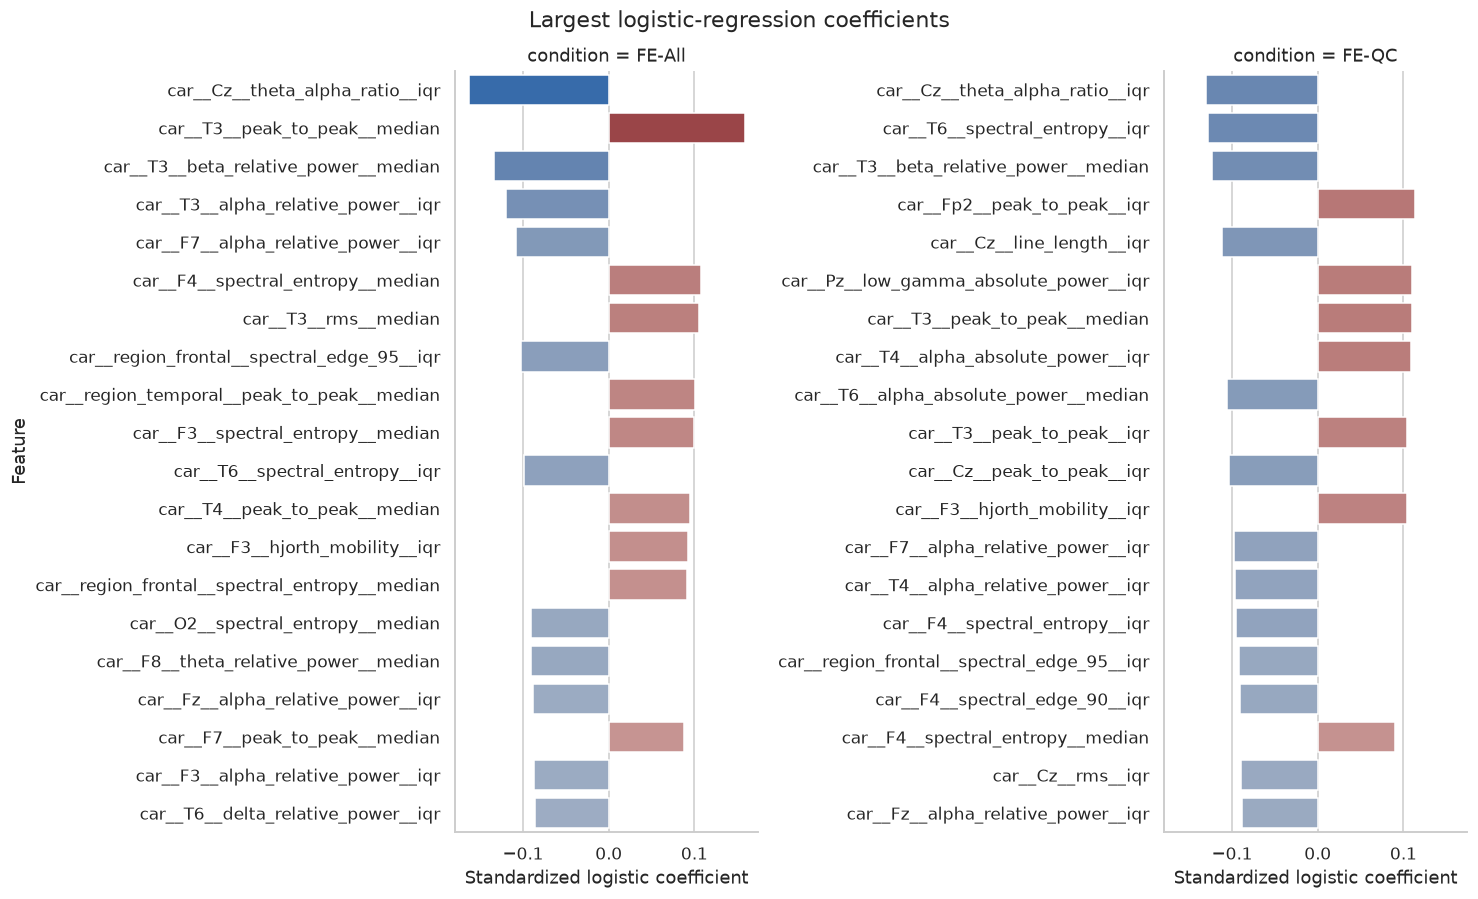

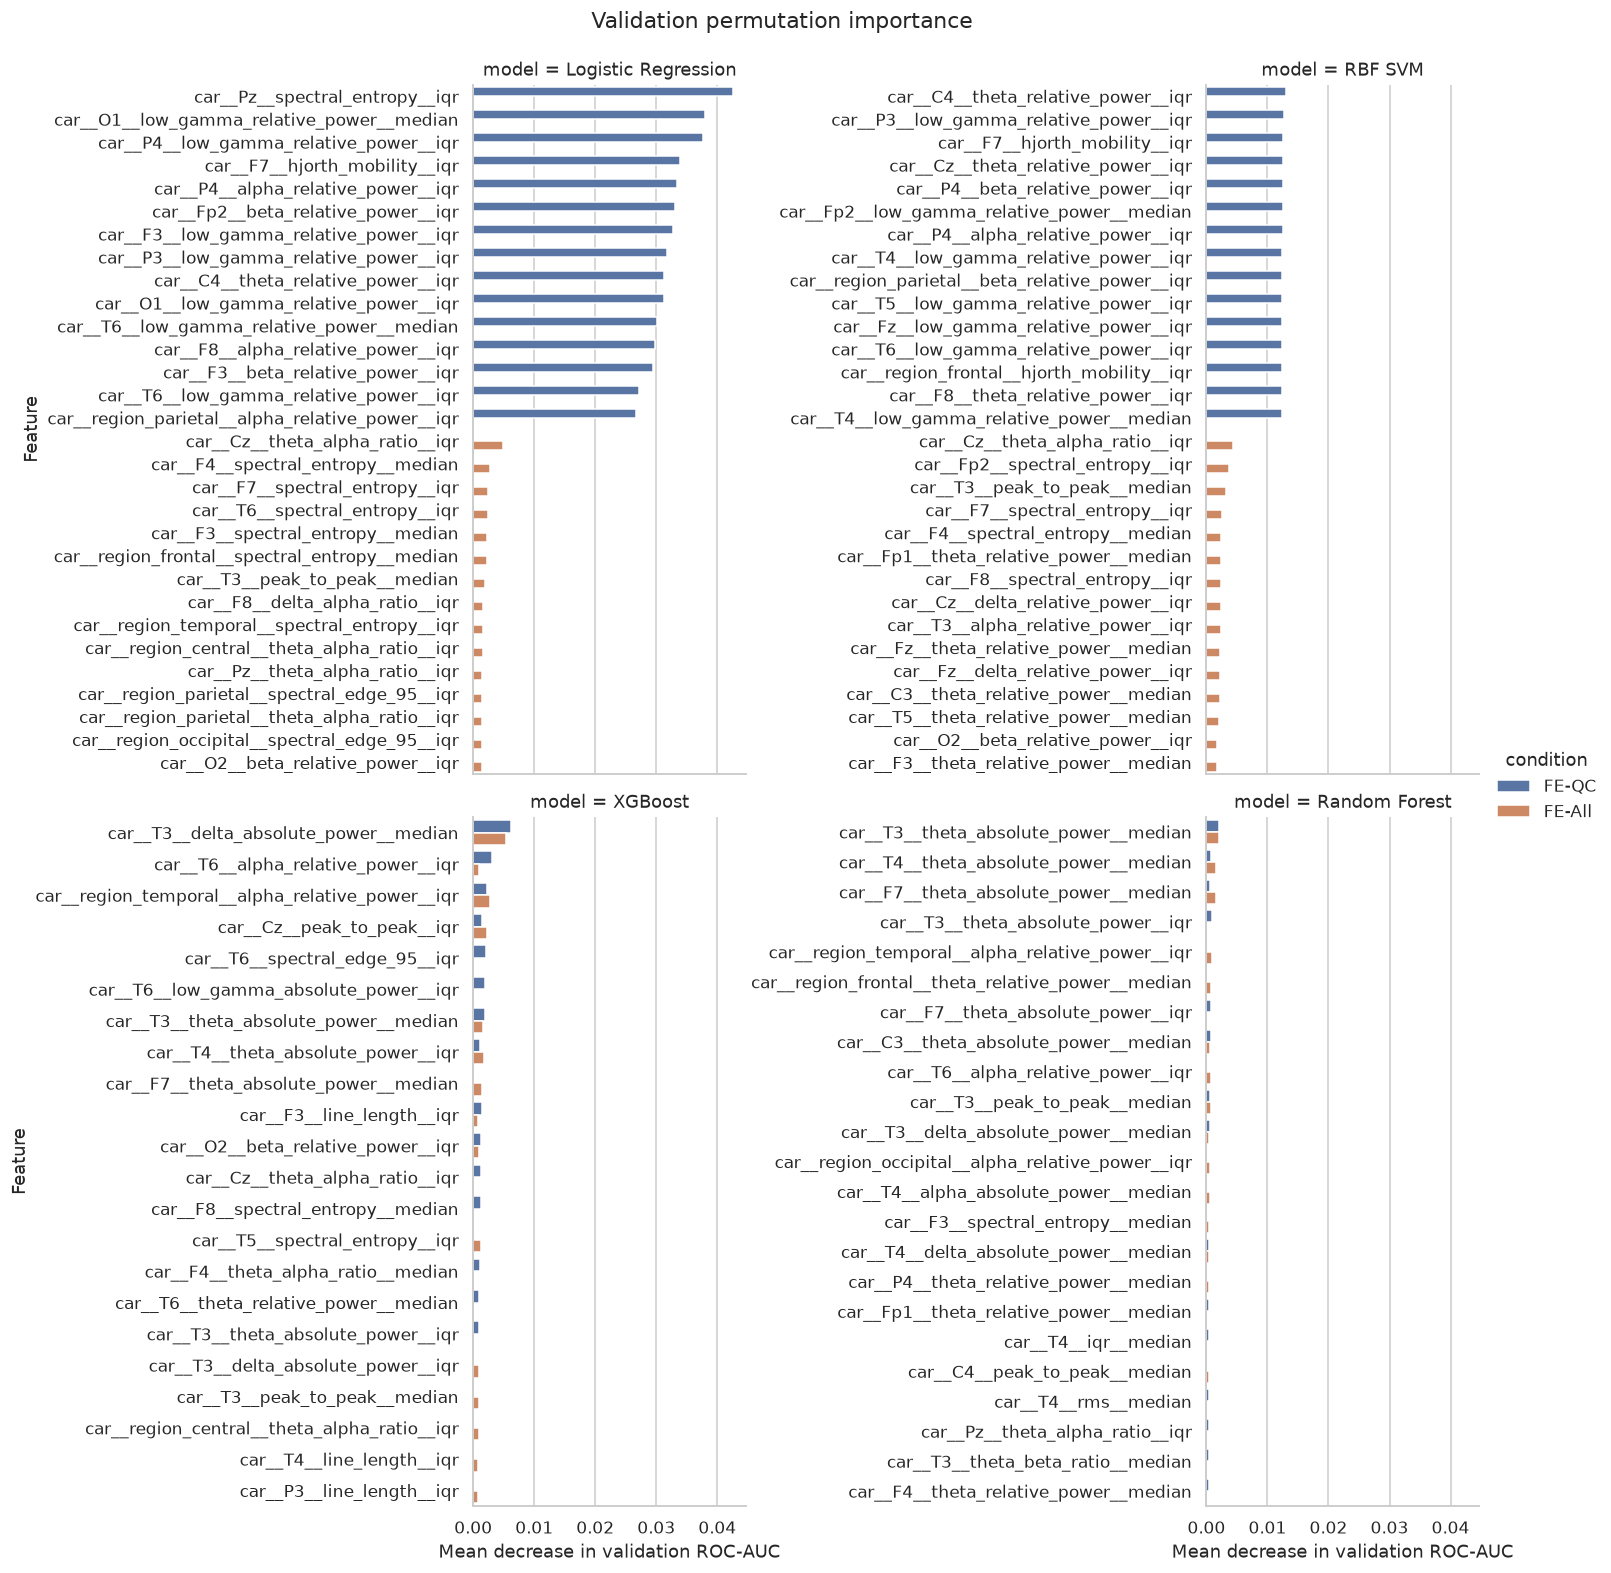

In [18]:
def transformed_base_feature_names(estimator: Pipeline) -> list[str]:
    imputer = estimator.named_steps["imputer"]
    names = list(FEATURE_COLUMNS)
    if getattr(imputer, "indicator_", None) is not None:
        names += [f"missing_indicator__{FEATURE_COLUMNS[i]}" for i in imputer.indicator_.features_]
    return names


def logistic_coefficients(search: GridSearchCV, condition: str) -> pd.DataFrame:
    estimator = search.best_estimator_
    classifier = estimator.named_steps["classifier"]
    names = transformed_base_feature_names(estimator)
    coefficients = classifier.coef_.ravel()
    assert len(names) == len(coefficients)
    return pd.DataFrame({
        "condition": condition, "feature": names, "coefficient": coefficients,
        "absolute_coefficient": np.abs(coefficients),
    }).sort_values("absolute_coefficient", ascending=False)


coef_all = logistic_coefficients(searches_all["Logistic Regression"], "FE-All")
coef_qc = logistic_coefficients(searches_qc["Logistic Regression"], "FE-QC")
coefficient_df = pd.concat([coef_all, coef_qc], ignore_index=True)
coefficient_df.to_csv(OUTPUT_DIRS["importance"] / "logistic_coefficients.csv", index=False)

top_coef = coefficient_df.groupby("condition", as_index=False, group_keys=False).head(20)
g = sns.catplot(data=top_coef, x="coefficient", y="feature", col="condition", kind="bar",
                sharey=False, height=8, aspect=0.85, palette="vlag", hue="coefficient", legend=False)
g.set_axis_labels("Standardized logistic coefficient", "Feature")
g.fig.suptitle("Largest logistic-regression coefficients", y=1.02)
save_figure(g.fig, "logistic_coefficients")
plt.show()


def compute_permutation_table(frame: pd.DataFrame, searches: dict, condition: str) -> pd.DataFrame:
    validation = frame.loc[frame["split"].eq("val")].reset_index(drop=True)
    rows = []
    for model_name, search in searches.items():
        if model_name == "Dummy":
            continue
        result = permutation_importance(
            search.best_estimator_, validation[FEATURE_COLUMNS], validation["target"],
            scoring="roc_auc", n_repeats=PERMUTATION_REPEATS, random_state=RANDOM_STATE, n_jobs=N_JOBS,
        )
        rows.extend({
            "condition": condition, "model": model_name, "feature": feature,
            "importance_mean": mean, "importance_sd": sd,
        } for feature, mean, sd in zip(FEATURE_COLUMNS, result.importances_mean, result.importances_std))
    return pd.DataFrame(rows)


permutation_all = compute_permutation_table(paired_all, searches_all, "FE-All")
permutation_qc = compute_permutation_table(paired_qc, searches_qc, "FE-QC")
permutation_df = pd.concat([permutation_all, permutation_qc], ignore_index=True)
permutation_df.to_parquet(OUTPUT_DIRS["importance"] / "validation_permutation_importance.parquet", index=False)

top_permutation = (
    permutation_df.sort_values("importance_mean", ascending=False)
    .groupby(["condition", "model"], as_index=False, group_keys=False).head(15)
)
g = sns.catplot(data=top_permutation, x="importance_mean", y="feature", hue="condition",
                col="model", col_wrap=2, kind="bar", sharey=False, height=7)
g.set_axis_labels("Mean decrease in validation ROC-AUC", "Feature")
g.fig.suptitle("Validation permutation importance", y=1.02)
save_figure(g.fig, "permutation_importance")
plt.show()

Logistic coefficients refer to standardized inputs and retain direction; permutation importance measures the decrease in validation ROC-AUC after shuffling one feature. Correlated predictors can substitute for one another, making single-feature importance appear small or unstable. Neither measure establishes causal physiology or clinical localization.

## 19. Frequency-band, feature-family, and regional analysis

,family,band,region,features
0,regional,alpha,central,4
1,regional,alpha,frontal,4
2,regional,alpha,occipital,4
3,regional,alpha,parietal,4
4,regional,alpha,temporal,4
5,regional,beta,central,4
6,regional,beta,frontal,4
7,regional,beta,occipital,4
8,regional,beta,parietal,4
9,regional,beta,temporal,4


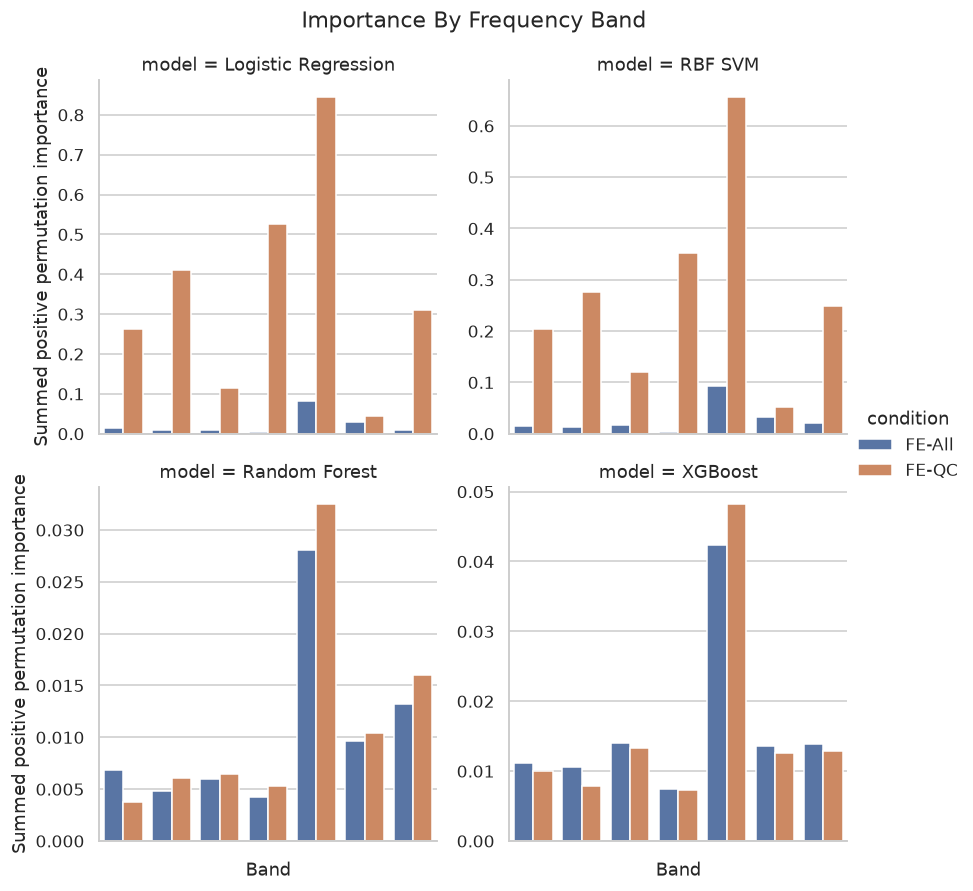

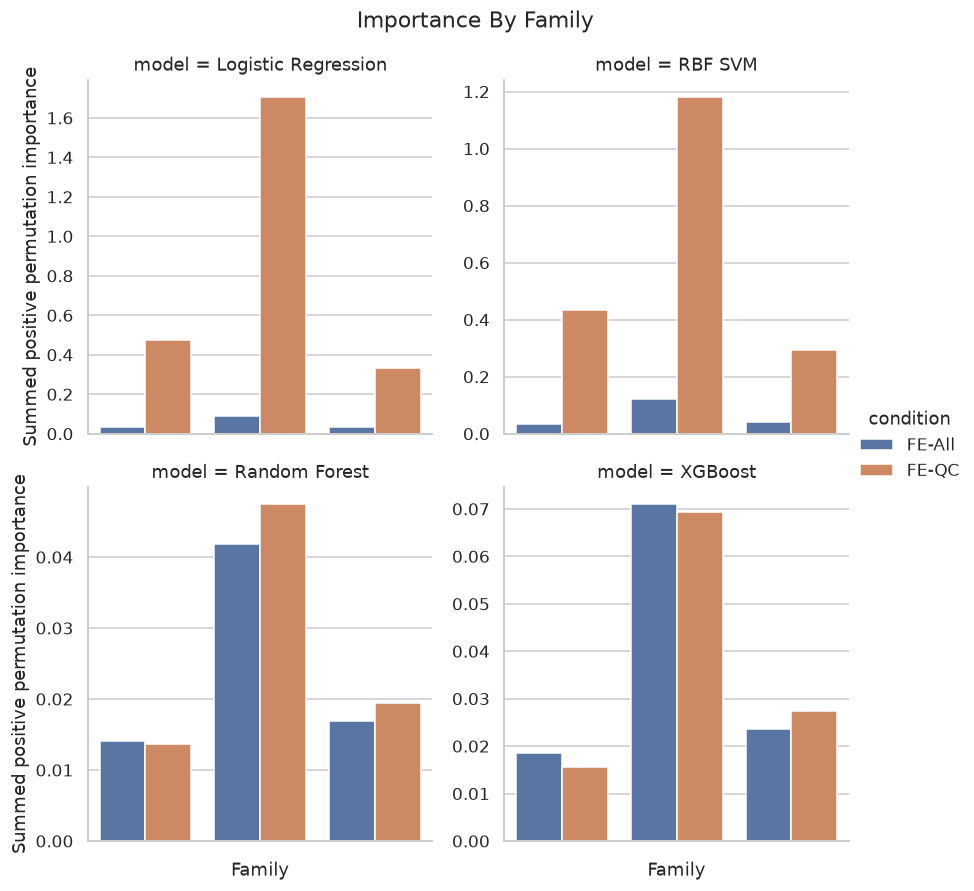

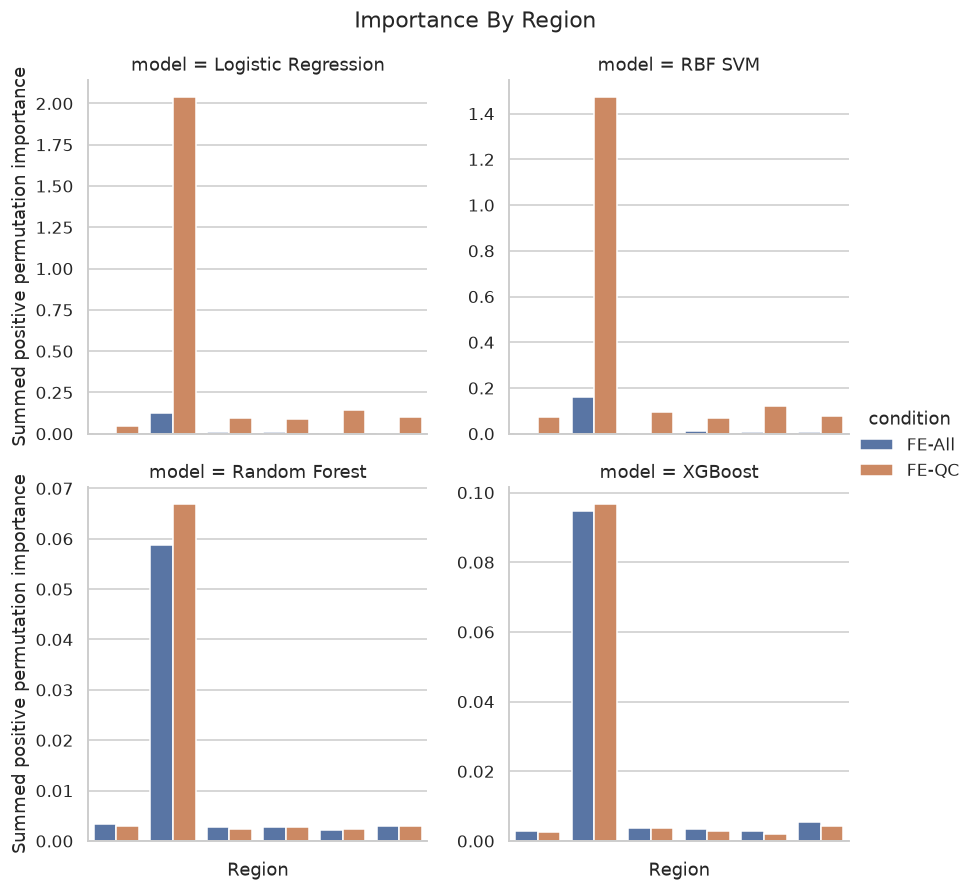

In [19]:
BANDS = ["delta", "theta", "alpha", "beta", "low_gamma"]
REGIONS = ["frontal", "central", "temporal", "parietal", "occipital"]
TEMPORAL_FEATURES = {"rms", "iqr", "mad", "line_length", "peak_to_peak", "hjorth_mobility", "hjorth_complexity"}


def describe_feature(feature: str) -> dict:
    lowered = feature.lower()
    parts = lowered.split("__")
    feature_name = parts[-2] if len(parts) >= 2 else lowered
    if feature_name.endswith("_ratio"):
        band = "power_ratio"
    else:
        band = next((band for band in BANDS if feature_name.startswith(f"{band}_")), "non_band")
    region = next((region for region in REGIONS if f"__region_{region}__" in lowered), "channel_level")
    if region != "channel_level":
        family = "regional"
    elif feature_name in TEMPORAL_FEATURES:
        family = "temporal"
    else:
        family = "spectral"
    return {"band": band, "region": region, "family": family}


feature_taxonomy = pd.DataFrame([{"feature": feature, **describe_feature(feature)} for feature in FEATURE_COLUMNS])
assert feature_taxonomy["feature"].is_unique
region_feature_counts = feature_taxonomy.loc[feature_taxonomy["region"].ne("channel_level"), "region"].value_counts()
assert region_feature_counts.reindex(REGIONS).eq(48).all(), f"Unexpected regional feature counts: {region_feature_counts.to_dict()}"
assert feature_taxonomy["family"].eq("regional").sum() == 240
display(feature_taxonomy.groupby(["family", "band", "region"]).size().rename("features").reset_index())

importance_annotated = permutation_df.merge(feature_taxonomy, on="feature", validate="many_to_one")
grouped_importance = (
    importance_annotated.groupby(["condition", "model", "family", "band", "region"], as_index=False)
    .agg(total_positive_importance=("importance_mean", lambda s: s.clip(lower=0).sum()),
         mean_importance=("importance_mean", "mean"), features=("feature", "size"))
)
grouped_importance.to_csv(OUTPUT_DIRS["importance"] / "grouped_importance.csv", index=False)

for grouping, stem in [("band", "importance_by_frequency_band"), ("family", "importance_by_family"), ("region", "importance_by_region")]:
    plot_data = (
        importance_annotated.assign(positive_importance=lambda d: d["importance_mean"].clip(lower=0))
        .groupby(["condition", "model", grouping], as_index=False)
        .agg(group_importance=("positive_importance", "sum"))
    )
    g = sns.catplot(data=plot_data, x=grouping, y="group_importance", hue="condition",
                    col="model", col_wrap=2, kind="bar", height=4, sharey=False)
    g.set_xticklabels(rotation=25)
    g.set_axis_labels(grouping.replace("_", " ").title(), "Summed positive permutation importance")
    g.fig.suptitle(stem.replace("_", " ").title(), y=1.03)
    save_figure(g.fig, stem)
    plt.show()

Grouped summaries reduce—but do not eliminate—the instability caused by correlated features. Summed positive permutation effects depend on group size and are descriptive. Regional features are derived summaries, while “channel-level” includes individual electrodes; neither category directly measures a localized neural generator.

## 20. Regional ablation experiments

/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

,condition,model,ablation,features,roc_auc,delta_from_baseline
0,FE-All,Logistic Regression,none,1152,0.904149,NaN
1,FE-All,Logistic Regression,remove_frontal,768,0.889664,-0.014485
2,FE-All,Logistic Regression,remove_central,960,0.902449,-0.001700
3,FE-All,Logistic Regression,remove_temporal,912,0.894543,-0.009606
4,FE-All,Logistic Regression,remove_parietal,960,0.902090,-0.002059
5,FE-All,Logistic Regression,remove_occipital,1008,0.908074,0.003925
6,FE-All,XGBoost,none,1152,0.906291,NaN
7,FE-All,XGBoost,remove_frontal,768,0.900196,-0.006095
8,FE-All,XGBoost,remove_central,960,0.904177,-0.002115
9,FE-All,XGBoost,remove_temporal,912,0.903375,-0.002916


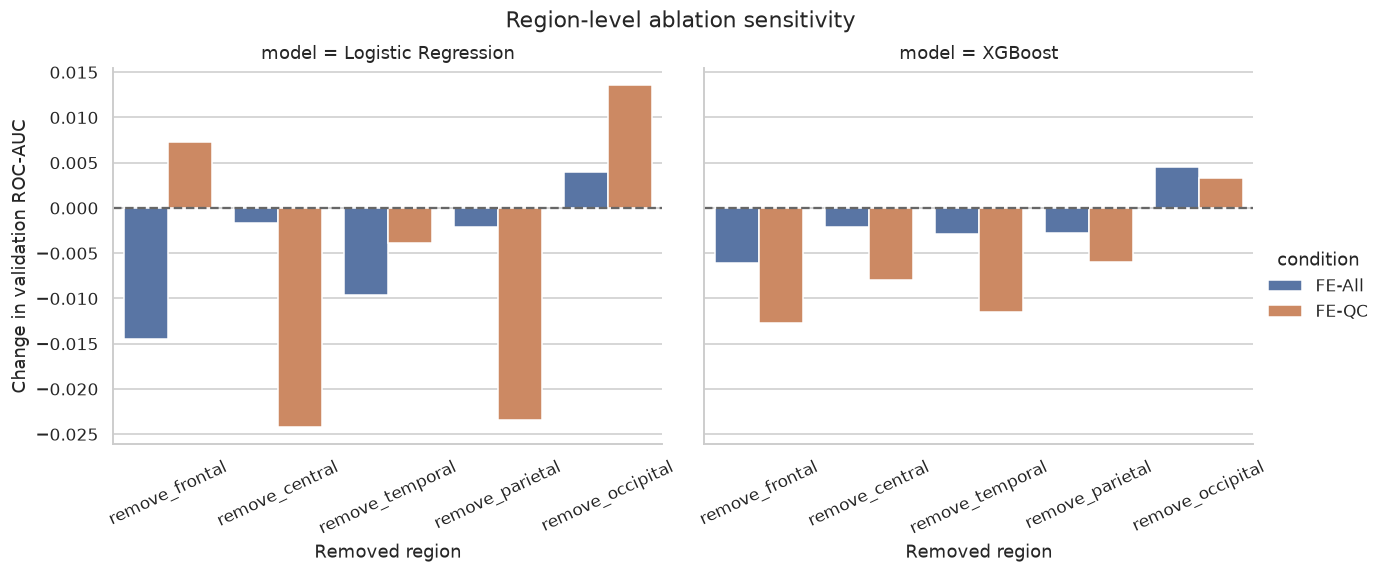

In [20]:
REGION_CHANNELS = {
    "frontal": ["Fp1", "Fp2", "F3", "F4", "F7", "F8", "Fz"],
    "central": ["C3", "C4", "Cz"],
    "temporal": ["T3", "T4", "T5", "T6"],
    "parietal": ["P3", "P4", "Pz"],
    "occipital": ["O1", "O2"],
}


def columns_for_region(region: str) -> list[str]:
    channels = REGION_CHANNELS[region]
    markers = [f"__region_{region}__", *[f"__{channel}__" for channel in channels]]
    selected = [feature for feature in FEATURE_COLUMNS if any(marker in feature for marker in markers)]
    assert selected, f"No predictors matched region: {region}"
    return selected


def run_region_ablation(frame: pd.DataFrame, search: GridSearchCV, condition: str, model_name: str) -> pd.DataFrame:
    train = frame.loc[frame["split"].eq("train")]
    validation = frame.loc[frame["split"].eq("val")]
    baseline = roc_auc_score(validation["target"], positive_probability(search.best_estimator_, validation[FEATURE_COLUMNS]))
    rows = [{"condition": condition, "model": model_name, "ablation": "none", "features": len(FEATURE_COLUMNS), "roc_auc": baseline}]
    for region in REGIONS:
        removed = set(columns_for_region(region))
        retained = [feature for feature in FEATURE_COLUMNS if feature not in removed]
        estimator = clone(search.best_estimator_)
        estimator.fit(train[retained], train["target"])
        auc = roc_auc_score(validation["target"], positive_probability(estimator, validation[retained]))
        rows.append({
            "condition": condition, "model": model_name, "ablation": f"remove_{region}",
            "features": len(retained), "roc_auc": auc, "delta_from_baseline": auc - baseline,
        })
    return pd.DataFrame(rows)


ABLATION_MODELS = ["Logistic Regression", "XGBoost"]
ablation_tables = []
for condition, frame, searches in [
    ("FE-All", paired_all, searches_all),
    ("FE-QC", paired_qc, searches_qc),
]:
    for model_name in ABLATION_MODELS:
        ablation_tables.append(run_region_ablation(frame, searches[model_name], condition, model_name))
regional_ablation_df = pd.concat(ablation_tables, ignore_index=True)
regional_ablation_df.to_csv(OUTPUT_DIRS["importance"] / "regional_ablation.csv", index=False)
display(regional_ablation_df)

plot_ablation = regional_ablation_df.loc[regional_ablation_df["ablation"].ne("none")]
g = sns.catplot(data=plot_ablation, x="ablation", y="delta_from_baseline", hue="condition",
                col="model", kind="bar", height=4.5, aspect=1.3)
for ax in g.axes.flat: ax.axhline(0, color="0.4", linestyle="--")
g.set_xticklabels(rotation=25)
g.set_axis_labels("Removed region", "Change in validation ROC-AUC")
g.fig.suptitle("Region-level ablation sensitivity", y=1.03)
save_figure(g.fig, "regional_ablation")
plt.show()

Ablation refits each selected model after removing both regional summaries and channel-level features associated with one anatomical region. A performance decrease indicates reliance on that predictor group, not causal or anatomically specific pathology. Overlapping information and correlated regions can mask importance.

## 21. Secondary full-cohort FE-All experiment

In [21]:
# This experiment is reported separately because it includes 14 recordings unavailable to FE-QC.
full_train = full_all.loc[full_all["split"].eq("train")].reset_index(drop=True)
full_cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(
    full_train[FEATURE_COLUMNS], full_train["target"], full_train["patient_id"]
))
for train_idx, test_idx in full_cv:
    assert set(full_train.loc[train_idx, "patient_id"]).isdisjoint(full_train.loc[test_idx, "patient_id"])

searches_full, grid_full, folds_full = run_grouped_searches(full_all, "FE-All-full", full_cv)
grid_full.to_csv(OUTPUT_DIRS["cv"] / "full_cohort_hyperparameter_results.csv", index=False)
folds_full.to_csv(OUTPUT_DIRS["cv"] / "full_cohort_fold_scores.csv", index=False)
display(folds_full.groupby("model")["roc_auc"].agg(["mean", "std"]).sort_values("mean", ascending=False))

full_val_predictions, full_val_metrics, thresholds_full = validation_predictions(
    full_all, searches_full, "FE-All-full"
)
full_val_predictions.to_parquet(OUTPUT_DIRS["validation"] / "full_cohort_recording_predictions.parquet", index=False)
full_val_metrics.to_csv(OUTPUT_DIRS["validation"] / "full_cohort_metrics.csv", index=False)
display(full_val_metrics.sort_values("roc_auc", ascending=False))

[FE-All-full] searching Dummy ...
[FE-All-full] searching Logistic Regression ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

[FE-All-full] searching RBF SVM ...


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


[FE-All-full] searching Random Forest ...
[FE-All-full] searching XGBoost ...


,mean,std
model,,
XGBoost,0.920167,0.009392
RBF SVM,0.908877,0.008382
Random Forest,0.906805,0.014458
Logistic Regression,0.900998,0.009489
Dummy,0.500000,0.000000


,condition,model,roc_auc,balanced_accuracy,sensitivity,specificity,precision,f1,threshold,tn,fp,fn,tp
2,FE-All-full,RBF SVM,0.908367,0.832671,0.825926,0.839416,0.835206,0.830540,0.447197,230,44,47,223
4,FE-All-full,XGBoost,0.907353,0.834009,0.759259,0.908759,0.891304,0.820000,0.573320,249,25,65,205
1,FE-All-full,Logistic Regression,0.897391,0.832374,0.785185,0.879562,0.865306,0.823301,0.480222,241,33,58,212
3,FE-All-full,Random Forest,0.895418,0.823466,0.814815,0.832117,0.827068,0.820896,0.452856,228,46,50,220
0,FE-All-full,Dummy,0.500000,0.500000,1.000000,0.000000,0.496324,0.663391,0.495168,0,274,0,270


The full FE-All experiment assesses operational performance on all 2,993 recordings. Its results must remain separate from the paired analysis because cohort composition differs; any change combines cohort and sampling effects.

## 22. Final evaluation — locked

In [22]:
def refit_and_evaluate_locked(
    frame: pd.DataFrame,
    searches: dict[str, GridSearchCV],
    thresholds: dict[str, float],
    condition: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    development = frame.loc[frame["split"].isin(["train", "val"])].reset_index(drop=True)
    evaluation = frame.loc[frame["split"].eq("eval")].reset_index(drop=True)
    prediction_tables, metric_rows = [], []
    for model_name, search in searches.items():
        estimator = clone(search.best_estimator_)
        estimator.fit(development[FEATURE_COLUMNS], development["target"])
        probability = positive_probability(estimator, evaluation[FEATURE_COLUMNS])
        threshold = thresholds[model_name]  # selected previously from validation predictions
        metric_rows.append({"condition": condition, "model": model_name, **binary_metrics(
            evaluation["target"].to_numpy(), probability, threshold
        )})
        prediction_tables.append(pd.DataFrame({
            "filepath": evaluation["filepath"], "patient_id": evaluation["patient_id"],
            "label": evaluation["label"], "target": evaluation["target"],
            "condition": condition, "model": model_name, "probability": probability,
            "prediction": (probability >= threshold).astype(int), "threshold": threshold,
        }))
        joblib.dump(estimator, OUTPUT_DIRS["final"] / f"{condition}_{model_name.replace(' ', '_')}.joblib")
    return pd.concat(prediction_tables, ignore_index=True), pd.DataFrame(metric_rows)


if not RUN_FINAL_EVALUATION:
    print("FINAL EVALUATION REMAINS LOCKED. Set RUN_FINAL_EVALUATION = True only after protocol freeze.")
else:
    final_pred_all, final_metrics_all = refit_and_evaluate_locked(paired_all, searches_all, thresholds_all, "FE-All")
    final_pred_qc, final_metrics_qc = refit_and_evaluate_locked(paired_qc, searches_qc, thresholds_qc, "FE-QC")
    final_pred_full, final_metrics_full = refit_and_evaluate_locked(full_all, searches_full, thresholds_full, "FE-All-full")
    final_predictions_df = pd.concat([final_pred_all, final_pred_qc, final_pred_full], ignore_index=True)
    final_metrics_df = pd.concat([final_metrics_all, final_metrics_qc, final_metrics_full], ignore_index=True)

    final_clustered_rows = []
    for (condition, model), group in final_predictions_df.groupby(["condition", "model"]):
        threshold = float(group["threshold"].iloc[0])
        low, high = patient_cluster_bootstrap_auc(group)
        final_clustered_rows.append({
            "condition": condition,
            "model": model,
            **binary_metrics(group["target"].to_numpy(), group["probability"].to_numpy(), threshold),
            "roc_auc_ci_low": low,
            "roc_auc_ci_high": high,
            "recordings": group["filepath"].nunique(),
            "patients": group["patient_id"].nunique(),
            "estimand": "recording_level_with_patient_clustered_ci",
        })
    final_clustered_metrics_df = pd.DataFrame(final_clustered_rows)
    final_predictions_df.to_parquet(OUTPUT_DIRS["final"] / "recording_predictions.parquet", index=False)
    final_metrics_df.to_csv(OUTPUT_DIRS["final"] / "recording_metrics.csv", index=False)
    final_clustered_metrics_df.to_csv(
        OUTPUT_DIRS["final"] / "recording_metrics_patient_clustered_ci.csv", index=False
    )
    display(final_metrics_df)
    display(final_clustered_metrics_df)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for condition, linestyle in [("FE-All", "-"), ("FE-QC", "--")]:
        for model_name in MODEL_NAMES:
            subset = final_predictions_df.query("condition == @condition and model == @model_name")
            fpr, tpr, _ = roc_curve(subset["target"], subset["probability"])
            axes[0].plot(fpr, tpr, linestyle=linestyle, color=MODEL_COLORS[model_name], alpha=0.85,
                         label=f"{model_name} / {condition}")
    axes[0].plot([0, 1], [0, 1], "--", color="0.6")
    axes[0].set(title="Locked evaluation ROC curves", xlabel="False-positive rate", ylabel="True-positive rate")
    axes[0].legend(fontsize=7)
    sns.barplot(data=final_metrics_df, x="model", y="balanced_accuracy", hue="condition", ax=axes[1])
    axes[1].set(title="Locked evaluation balanced accuracy", xlabel="Model", ylabel="Balanced accuracy")
    axes[1].tick_params(axis="x", rotation=20)
    save_figure(fig, "final_evaluation_performance", final=True)
    plt.show()

FINAL EVALUATION REMAINS LOCKED. Set RUN_FINAL_EVALUATION = True only after protocol freeze.


This section is intentionally inert by default. Once unlocked, it refits already selected configurations on train plus validation data, applies thresholds chosen before evaluation access, and produces recording- and patient-level outputs. No tuning, feature selection, threshold optimization, or interpretability analysis may use evaluation results.

## 23. Results export and reproducibility metadata

In [23]:
run_metadata = {
    "run_id": RUN_ID,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(PROJECT_ROOT),
    "feature_paths": {"FE-All": str(FE_ALL_PATH), "FE-QC": str(FE_QC_PATH)},
    "random_state": RANDOM_STATE,
    "n_splits": N_SPLITS,
    "permutation_repeats": PERMUTATION_REPEATS,
    "n_jobs": N_JOBS,
    "run_final_evaluation": RUN_FINAL_EVALUATION,
    "feature_count": len(FEATURE_COLUMNS),
    "models": MODEL_NAMES,
    "param_grids": PARAM_GRIDS,
    "python": sys.version,
    "platform": platform.platform(),
    "package_versions": {
        "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__, "seaborn": sns.__version__,
    },
}
(RUN_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2, default=str), encoding="utf-8")
(RUN_DIR / "feature_columns.json").write_text(json.dumps(FEATURE_COLUMNS, indent=2), encoding="utf-8")
print("Results directory:", RUN_DIR)
print("Figures directory:", FIGURE_DIR)

Results directory: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/ml_baselines/20261022T223917Z
Figures directory: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/figures/ML-Baselines


## 24. Scientific limitations and reproducibility checklist

### Limitations

- These are recording-level engineered-feature baselines, not end-to-end EEG models.
- FE-QC may remove disease-related signal as well as technical artifact; abnormal recordings have lower mean epoch acceptance in the existing audit.
- The 14 zero-accepted recordings prevent a complete-cohort FE-QC analysis without an explicit missing-data policy.
- The 1,152 predictors are highly correlated relative to 2,173 training recordings. Regularization and fold-contained feature selection are necessary for later reduced-feature experiments.
- The low-gamma band (30–40 Hz) lies near the preprocessing low-pass boundary and requires a prespecified ablation.
- Permutation importance, coefficients, and regional ablation indicate predictive reliance, not causality or clinical localization.
- Validation-selected models and thresholds must be reported separately from the final locked evaluation.

### Reproducibility checklist

- [ ] Confirm all integrity assertions pass.
- [ ] Record package versions and the run identifier.
- [ ] Verify patient independence across predefined splits and all CV folds.
- [ ] Keep preprocessing, imputation, scaling, and later feature selection inside CV pipelines.
- [ ] Use identical paired records, folds, search spaces, and budgets for FE-All and FE-QC.
- [ ] Report recording- and patient-level results with patient-clustered uncertainty.
- [ ] Report QC subgroup sizes and avoid strong claims from small subgroups.
- [ ] Keep QC coverage out of model predictors.
- [ ] Complete protocol and analysis decisions before unlocking evaluation.
- [ ] Run low-gamma and reduced-feature sensitivity analyses without consulting evaluation results.
- [ ] Preserve all exported tables, figures, model configurations, and run metadata.

### Execution order

Run the notebook sequentially through the validation, QC-sensitivity, and interpretability sections. Review the exported development results and freeze all decisions. Only then set `RUN_FINAL_EVALUATION = True` and run the locked section once.